# Atelier 1 : Apprentissage Supervisé avec Python (Credit Scoring)


**Objectif :** Dans cet atelier, nous allons expérimenter des algorithmes de traitement de données pour répondre à un problème de **crédit scoring** (classification binaire). L'objectif est de construire un classifieur capable de prédire la solvabilité d'un client (Status).

**Étapes du TP :**
1. **Data Preprocessing :** Chargement, analyse, transformation Numpy, et séparation Train/Test.
2. **Classification :** Comparaison de 3 modèles (CART, KNN, MLP).
3. **Feature Engineering :** Normalisation, ACP.
4. **Feature Selection :** Importance des variables (Random Forest).
5. **Pipeline :** Optimisation et sauvegarde du modèle.

**Trinome du TP :**
- CHARIF Taha Khalil : p2512972
- DJOUADI Hanane : p2512986
- MEZAOUROU Sidali : p2515000

## Import des bibliothèques nécessaires

In [81]:
# Importer la bibliothèque NumPy pour le calcul numérique et les tableaux multidimensionnels
import numpy as np
# Configurer les options d'affichage de NumPy :
# - threshold=10000 : augmente le seuil d'affichage avant troncature à 10000 éléments
# - suppress=True : désactive la notation scientifique pour les petits/ grands nombres
np.set_printoptions(threshold=10000, suppress=True)

# Importer la bibliothèque Pandas pour la manipulation et l'analyse de données tabulaires
import pandas as pd

# Importer le module warnings pour gérer les avertissements
import warnings

# Importer la bibliothèque Matplotlib pour la création de visualisations et de graphiques
import matplotlib.pyplot as plt

# Ignorer tous les avertissements pour éviter l'encombrement de la sortie
warnings.filterwarnings('ignore')

In [82]:
# Importer la fonction train_test_split pour diviser les données en ensembles d'entraînement et de test
from sklearn.model_selection import train_test_split

# Importer le classifieur d'arbre de décision pour les modèles basés sur des règles de décision
from sklearn.tree import DecisionTreeClassifier

# Importer le classifieur des k-plus proches voisins (KNN) basé sur la similarité des instances
from sklearn.neighbors import KNeighborsClassifier

# Importer le classifieur de perceptron multicouche (réseau de neurones artificiels)
from sklearn.neural_network import MLPClassifier

# Importer diverses métriques d'évaluation pour les modèles de classification :
# - confusion_matrix : matrice de confusion pour visualiser les performances
# - classification_report : rapport détaillé avec précision, rappel, F1-score
# - roc_curve : courbe ROC (Receiver Operating Characteristic)
# - auc : calcul de l'aire sous la courbe ROC
# - accuracy_score : précision globale
# - precision_score : précision par classe
# - recall_score : rappel par classe
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, accuracy_score, precision_score, recall_score

# Importer la bibliothèque Seaborn pour des visualisations statistiques améliorées et esthétiques
import seaborn as sns

# Importer des méthodes de prétraitement des données :
# - StandardScaler : normalisation centrée réduite (moyenne=0, écart-type=1)
# - MinMaxScaler : normalisation min-max (mise à l'échelle dans un intervalle, souvent [0,1])
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Importer l'Analyse en Composantes Principales (PCA) pour la réduction de dimensionnalité
from sklearn.decomposition import PCA

## I. Chargement et Préparation des Données

Nous commençons par importer le jeu de données `credit_scoring.csv`. 
Conformément aux instructions :
1. Conversion du DataFrame Pandas en **Numpy Array**.
2. Séparation des variables caractéristiques (**X**) et de la variable cible à prédire (**y** = Status).
3. Analyse des propriétés (taille de l'échantillon, distribution des classes).

### Chargement des données avec pandas


In [ ]:
# Charger le fichier CSV "credit_scoring.csv" dans un DataFrame pandas
# Le séparateur de colonnes est le point-virgule (;) 
df = pd.read_csv("credit_scoring.csv", sep=';')

# Afficher les premières lignes pour inspection
# La méthode head() affiche par défaut les 5 premières lignes du DataFrame
print("Premières lignes du dataset")
print(df.head())
print("\n")  # Saut de ligne pour améliorer la lisibilité de la sortie

Premières lignes du dataset
   Seniority  Home  Time   Age  Marital  Records  Job  Expenses  Income  \
0        9.0   1.0  60.0  30.0      0.0      1.0  1.0      73.0   129.0   
1       17.0   1.0  60.0  58.0      1.0      1.0  0.0      48.0   131.0   
2       10.0   0.0  36.0  46.0      0.0      2.0  1.0      90.0   200.0   
3        0.0   1.0  60.0  24.0      1.0      1.0  0.0      63.0   182.0   
4        0.0   1.0  36.0  26.0      1.0      1.0  0.0      46.0   107.0   

   Assets  Debt  Amount   Price  Status  
0     0.0   0.0   800.0   846.0       1  
1     0.0   0.0  1000.0  1658.0       1  
2  3000.0   0.0  2000.0  2985.0       0  
3  2500.0   0.0   900.0  1325.0       1  
4     0.0   0.0   310.0   910.0       1  




### Transformation en numpy array


In [84]:
# 2. Transformation en numpy array
# Convertir le DataFrame pandas en tableau NumPy multidimensionnel
# .values extrait les données sous forme de tableau NumPy (sans les étiquettes de colonnes)
data_array = df.values

# Afficher le tableau NumPy résultant
# f-string permet d'insérer des expressions dans la chaîne de caractères
print(f" Transformation en numpy array\n {data_array}")

# Afficher le type de l'objet data_array pour vérifier la conversion
print(f"Type de data_array : {type(data_array)}")

 Transformation en numpy array
 [[   9.    1.   60. ...  800.  846.    1.]
 [  17.    1.   60. ... 1000. 1658.    1.]
 [  10.    0.   36. ... 2000. 2985.    0.]
 ...
 [   0.    0.   24. ...  500.  963.    0.]
 [   0.    1.   48. ...  550.  550.    1.]
 [   5.    0.   60. ... 1350. 1650.    1.]]
Type de data_array : <class 'numpy.ndarray'>


### Séparation des X et Y

In [85]:
# Séparation des caractéristiques (X) et de la variable cible (y)
# X : Toutes les caractéristiques (features) du dataset
# [:, :-1] : Sélectionne toutes les lignes (:) et toutes les colonnes sauf la dernière (:-1)
X = data_array[:, :-1]  # Toutes les colonnes sauf la dernière

# y : Variable cible (target) à prédire
# [:, -1] : Sélectionne toutes les lignes (:) et uniquement la dernière colonne (-1) qui contient 'status'
y = data_array[:, -1]   # Dernière colonne (status)

### Analyse du jeu de données

In [86]:
# Taille de l'échantillon
# Afficher la forme (dimensions) du DataFrame original
# .shape retourne un tuple (nombre_de_lignes, nombre_de_colonnes)
print(f"Shape du DataFrame original : {df.shape}")

# Afficher la forme du tableau des caractéristiques X
print(f"Shape de X (caractéristiques) : {X.shape}")

# Afficher la forme du tableau de la variable cible y
# Note: y.shape retournera (n,) pour un tableau 1D avec n éléments
print(f"Shape de y (target) : {y.shape}")

# Afficher le nombre total d'exemples (instances) dans le dataset
# X.shape[0] correspond au nombre de lignes dans X
print(f"Nombre total d'exemples : {X.shape[0]}")

# Afficher le nombre de caractéristiques (features) dans le dataset
# X.shape[1] correspond au nombre de colonnes dans X
print(f"Nombre de caractéristiques : {X.shape[1]}")

print("\n")  # Saut de ligne pour améliorer la lisibilité

Shape du DataFrame original : (4375, 14)
Shape de X (caractéristiques) : (4375, 13)
Shape de y (target) : (4375,)
Nombre total d'exemples : 4375
Nombre de caractéristiques : 13




In [87]:
# Analyse des valeurs uniques et leurs counts
# np.unique() avec return_counts=True retourne :
# - Les valeurs uniques dans le tableau y
# - Le nombre d'occurrences de chaque valeur unique
unique_values, counts = np.unique(y, return_counts=True)

# Afficher les différentes classes présentes dans la variable cible 'status'
print(f"Valeurs uniques dans 'status' : {unique_values}")

# Afficher le nombre d'occurrences pour chaque classe
print(f"Counts correspondants : {counts}")
print("\n")

# Calcul des pourcentages de chaque classe
# Total d'échantillons dans le dataset (longueur du tableau y)
total_samples = len(y)
print(f"Nombre total d'échantillons : {total_samples}")

Valeurs uniques dans 'status' : [0. 1.]
Counts correspondants : [1216 3159]


Nombre total d'échantillons : 4375


- On separera les données en ensembles d'entraînement et de test (80% / 20%) en utilisant `train_test_split` de scikit-learn avec un `random_state` fixé pour la reproductibilité.

In [88]:
# Analyse détaillée pour chaque classe
# Parcourir chaque valeur unique avec son compteur correspondant
# enumerate() ajoute un index (i) à chaque itération
# zip() combine les deux tableaux unique_values et counts
for i, (value, count) in enumerate(zip(unique_values, counts)):
    # Calcul du pourcentage de chaque classe par rapport au total
    percentage = (count / total_samples) * 100
    
    # Afficher les informations pour la classe courante
    print(f"Classe {value} :")
    print(f"  - Nombre d'exemples : {count}")
    # Formatage du pourcentage avec 2 décimales
    print(f"  - Pourcentage : {percentage:.2f}%")
    
    # Identification des classes positives et négatives
    # Vérifie si on a un problème de classification binaire (2 classes uniquement)
    if len(unique_values) == 2:
        if i == 0:
            # Par convention, la première classe (index 0) est souvent la classe négative
            print(f"  - Interprétation : Classe négative (mauvais crédit)")
        else:
            # La seconde classe (index 1) est la classe positive
            print(f"  - Interprétation : Classe positive (bon crédit)")
    print("")  # Ligne vide pour séparer les différentes classes

Classe 0.0 :
  - Nombre d'exemples : 1216
  - Pourcentage : 27.79%
  - Interprétation : Classe négative (mauvais crédit)

Classe 1.0 :
  - Nombre d'exemples : 3159
  - Pourcentage : 72.21%
  - Interprétation : Classe positive (bon crédit)



### Séparation Apprentissage / Test

Pour éviter de biaiser les résultats, nous séparons les données en deux parties égales (50% / 50%) :
* **X_train, y_train :** Pour l'entraînement des modèles.
* **X_test, y_test :** Pour l'évaluation des performances.
* *Note : Random state fixé à 1 pour la reproductibilité.*

In [89]:
# Séparation des données en train/test (50% chacune)
# Utilisation de la fonction train_test_split pour diviser les données
X_train, X_test, y_train, y_test = train_test_split(
    X, y,  # Données d'entrée et sortie à diviser
    test_size=0.5,  # 50% des données pour le test, 50% pour l'entraînement
    random_state=1,  # Graine aléatoire pour la reproductibilité des résultats
)

# Afficher les tailles des ensembles créés
print(f"Taille de l'ensemble d'apprentissage : {X_train.shape[0]} exemples")
print(f"Taille de l'ensemble de test : {X_test.shape[0]} exemples")

# Calculer et afficher les proportions train/test en pourcentage
# X_train.shape[0]/len(X)*100 : pourcentage d'échantillons dans l'entraînement
# X_test.shape[0]/len(X)*100 : pourcentage d'échantillons dans le test
print(f"Proportion train/test : {X_train.shape[0]/len(X)*100:.1f}% / {X_test.shape[0]/len(X)*100:.1f}%")
print("\n")  # Saut de ligne pour améliorer la lisibilité

Taille de l'ensemble d'apprentissage : 2187 exemples
Taille de l'ensemble de test : 2188 exemples
Proportion train/test : 50.0% / 50.0%




## II. Apprentissage et Évaluation de Modèles

Nous allons comparer trois algorithmes d'apprentissage supervisé sur ce jeu de données :
1.  **Arbre de décision (CART)** (`random_state=1`)
2.  **k-Plus-Proches-Voisins (KNN)** (avec $k=5$)
3.  **Perceptron Multicouche (MLP)** (2 couches cachées de 40 et 20 neurones).

In [90]:
# Dictionnaire des algorithmes
# Création d'un dictionnaire pour stocker différents modèles de classification
# Clé : nom de l'algorithme (chaîne de caractères)
# Valeur : instance du classifieur configuré
algorithms = {
    'CART': DecisionTreeClassifier(random_state=1),  # Arbre de décision avec graine fixe pour reproductibilité
    'KNN-5': KNeighborsClassifier(n_neighbors=5),    # K-plus proches voisins avec k=5
    'MLP': MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1, max_iter=1000)  # Perceptron multicouche avec 2 couches cachées (40 puis 20 neurones)
}

print("Algorithmes définis :")
# Parcourir le dictionnaire et afficher le nom de chaque algorithme
# .items() retourne les paires (clé, valeur) du dictionnaire
for name, model in algorithms.items():
    print(f"- {name}")

Algorithmes définis :
- CART
- KNN-5
- MLP


In [91]:
def evaluate_model(model, X_test, y_test, model_name):
    """
    Évalue un modèle et retourne les métriques
    
    Parameters:
    -----------
    model : modèle entraîné
        Classifieur scikit-learn déjà ajusté (fitted)
    X_test : array-like
        Caractéristiques de l'ensemble de test
    y_test : array-like
        Étiquettes réelles de l'ensemble de test
    model_name : str
        Nom du modèle pour référence
        
    Returns:
    --------
    dict : Dictionnaire contenant toutes les métriques d'évaluation calculées
    """
    # Prédictions
    # Prédiction des classes (0 ou 1)
    y_pred = model.predict(X_test)
    # Probabilités d'appartenance à la classe positive (seconde colonne)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    
    # Calcul des métriques de performance
    # Précision globale : proportion de prédictions correctes
    acc = accuracy_score(y_test, y_pred)
    # Précision : proportion de vrais positifs parmi les prédits positifs
    precision = precision_score(y_test, y_pred, zero_division=0)
    # Rappel (Recall) : proportion de vrais positifs parmi les réels positifs
    recall = recall_score(y_test, y_pred, zero_division=0)
    

    best_metric = recall  # Rappel choisi comme critère métier principal
    # parceque dans le contexte du crédit, minimiser les faux négatifs (refuser un bon crédit) est crucial.
    
    # Score final : moyenne arithmétique entre accuracy et rappel
    final_score = (acc + best_metric) / 2
    
    # Matrice de confusion
    # Tableau 2x2 montrant vrais/faux positifs/négatifs
    cm = confusion_matrix(y_test, y_pred)
    
    # Courbe ROC (Receiver Operating Characteristic)
    # Calcul des taux de faux positifs (FPR) et vrais positifs (TPR)
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    # Aire sous la courbe ROC (mesure de performance globale)
    roc_auc = auc(fpr, tpr)
    
    # Retourner toutes les métriques dans un dictionnaire
    return {
        'accuracy': acc,
        'precision': precision,
        'recall': recall,
        'best_metric': best_metric,
        'final_score': final_score,
        'confusion_matrix': cm,
        'fpr': fpr,
        'tpr': tpr,
        'roc_auc': roc_auc,
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba
    }

In [92]:
def plot_roc_curves(results):
    """
    Affiche toutes les courbes ROC sur le même graphique
    
    Parameters:
    -----------
    results : dict
        Dictionnaire contenant les résultats des modèles,
        où chaque valeur contient un sous-dictionnaire 'metrics'
        avec les données des courbes ROC
    """
    plt.figure(figsize=(10, 8))
    
    # Tracer la courbe ROC pour chaque modèle
    for name, result in results.items():
        metrics = result['metrics']
        # Tracer FPR vs TPR avec l'AUC dans la légende
        plt.plot(metrics['fpr'], metrics['tpr'], 
                label=f'{name} (AUC = {metrics["roc_auc"]:.3f})', linewidth=2)
    
    # Courbe de référence (classifieur aléatoire)
    # Ligne diagonale pointillée noire représentant une performance aléatoire
    plt.plot([0, 1], [0, 1], 'k--', label='Aléatoire (AUC = 0.500)', alpha=0.6)
    
    # Définir les limites des axes
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    
    # Ajouter les labels des axes
    plt.xlabel('Taux de Faux Positifs (FPR)', fontsize=12)
    plt.ylabel('Taux de Vrais Positifs (TPR)', fontsize=12)
    
    # Ajouter un titre au graphique
    plt.title('Courbes ROC - Comparaison des modèles', fontsize=14, fontweight='bold')
    
    # Afficher la légende en bas à droite
    plt.legend(loc="lower right")
    
    # Ajouter une grille pour faciliter la lecture
    plt.grid(True, alpha=0.3)
    
    # Afficher le graphique
    plt.show()


def plot_confusion_matrices(results):
    """
    Affiche les matrices de confusion côte à côte
    
    Parameters:
    -----------
    results : dict
        Dictionnaire contenant les résultats des modèles,
        où chaque valeur contient un sous-dictionnaire 'metrics'
        avec la matrice de confusion
    """
    # Créer une grille de sous-graphiques : 1 ligne, n colonnes (n = nombre de modèles)
    fig, axes = plt.subplots(1, len(results), figsize=(15, 4))
    
    # Gérer le cas où il n'y a qu'un seul modèle (axes n'est pas un tableau)
    if len(results) == 1:
        axes = [axes]
    
    # Parcourir chaque modèle et créer sa matrice de confusion
    for idx, (name, result) in enumerate(results.items()):
        # Extraire la matrice de confusion
        cm = result['metrics']['confusion_matrix']
        ax = axes[idx]
        
        # Utilisation de seaborn pour une meilleure visualisation
        # heatmap crée une visualisation colorée avec annotations
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                   cbar=False, square=True, annot_kws={'size': 14})
        
        # Ajouter un titre avec le nom du modèle et son accuracy
        ax.set_title(f'{name}\nAccuracy: {result["metrics"]["accuracy"]:.3f}', fontweight='bold')
        
        # Configurer les labels des axes
        ax.set_ylabel('Vraie étiquette')
        ax.set_xlabel('Étiquette prédite')
        
        # Définir les étiquettes des ticks (classes binaires)
        ax.set_xticklabels(['Négatif', 'Positif'])
        ax.set_yticklabels(['Négatif', 'Positif'], rotation=0)
    
    # Ajuster l'espacement entre les sous-graphiques
    plt.tight_layout()
    
    # Afficher la figure
    plt.show()

In [93]:
def run_classifiers_train_test(X_train, X_test, y_train, y_test):
    """
    Entraîne et évalue tous les classifieurs du dictionnaire
    
    Parameters:
    -----------
    X_train, X_test : array-like
        Caractéristiques des ensembles d'entraînement et de test
    y_train, y_test : array-like
        Étiquettes des ensembles d'entraînement et de test
        
    Returns:
    --------
    best_model : modèle
        Le meilleur modèle selon le score final
    best_model_name : str
        Le nom du meilleur modèle
    results : dict
        Dictionnaire contenant tous les résultats d'évaluation
    """
    results = {}  # Dictionnaire pour stocker les résultats de tous les modèles
    best_model = None  # Initialisation du meilleur modèle
    best_score = -1  # Initialisation du meilleur score (valeur basse pour être dépassée)
    best_model_name = ""  # Nom du meilleur modèle
    
    print("=== APPRENTISSAGE ET ÉVALUATION DES MODÈLES ===")
    print("=" * 60)
    
    # Boucle sur tous les algorithmes définis dans le dictionnaire 'algorithms'
    for name, model in algorithms.items():
        print(f"\n {name}")
        print("-" * 30)
        
        # Entraînement du modèle sur les données d'entraînement
        model.fit(X_train, y_train)
        
        # Évaluation du modèle sur les données de test
        eval_results = evaluate_model(model, X_test, y_test, name)
        
        # Stockage des résultats (modèle et métriques)
        results[name] = {
            'model': model,
            'metrics': eval_results
        }
        
        # Affichage détaillé des métriques de performance
        print(f"Accuracy:    {eval_results['accuracy']:.4f}")
        print(f"Precision:   {eval_results['precision']:.4f}")
        print(f"Recall:      {eval_results['recall']:.4f}")
        print(f"Score final: {eval_results['final_score']:.4f} (Accuracy + Recall)/2")
        print(f"AUC:         {eval_results['roc_auc']:.4f}")
        
        # Mise à jour du meilleur modèle basé sur le score final
        if eval_results['final_score'] > best_score:
            best_score = eval_results['final_score']
            best_model = model
            best_model_name = name
    
    # Affichage comparatif de tous les modèles
    print("\n" + "=" * 60)
    print("COMPARAISON DES MODÈLES")
    print("=" * 60)
    for name in results:
        score = results[name]['metrics']['final_score']
        print(f"{name:10} : {score:.4f}")  # :10 pour aligner les noms
    
    print(f"\n MEILLEUR MODÈLE: {best_model_name} avec un score de {best_score:.4f}")
    
    return best_model, best_model_name, results

In [94]:
# EXÉCUTION PRINCIPALE
print("Début de l'apprentissage...")

# Appel de la fonction principale qui entraîne et évalue tous les classifieurs
# La fonction retourne :
# 1. Le meilleur modèle (instance du classifieur)
# 2. Le nom du meilleur modèle (chaîne de caractères)
# 3. Tous les résultats d'évaluation (dictionnaire)
best_model, best_model_name, all_results = run_classifiers_train_test(
    X_train, X_test, y_train, y_test  # Les données préparées précédemment
)

Début de l'apprentissage...
=== APPRENTISSAGE ET ÉVALUATION DES MODÈLES ===

 CART
------------------------------
Accuracy:    0.7271
Precision:   0.8194
Recall:      0.7992
Score final: 0.7632 (Accuracy + Recall)/2
AUC:         0.6687

 KNN-5
------------------------------
Accuracy:    0.7249
Precision:   0.7710
Recall:      0.8819
Score final: 0.8034 (Accuracy + Recall)/2
AUC:         0.6568

 MLP
------------------------------
Accuracy:    0.7367
Precision:   0.8051
Recall:      0.8396
Score final: 0.7882 (Accuracy + Recall)/2
AUC:         0.7242

COMPARAISON DES MODÈLES
CART       : 0.7632
KNN-5      : 0.8034
MLP        : 0.7882

 MEILLEUR MODÈLE: KNN-5 avec un score de 0.8034



VISUALISATIONS

Courbes ROC :


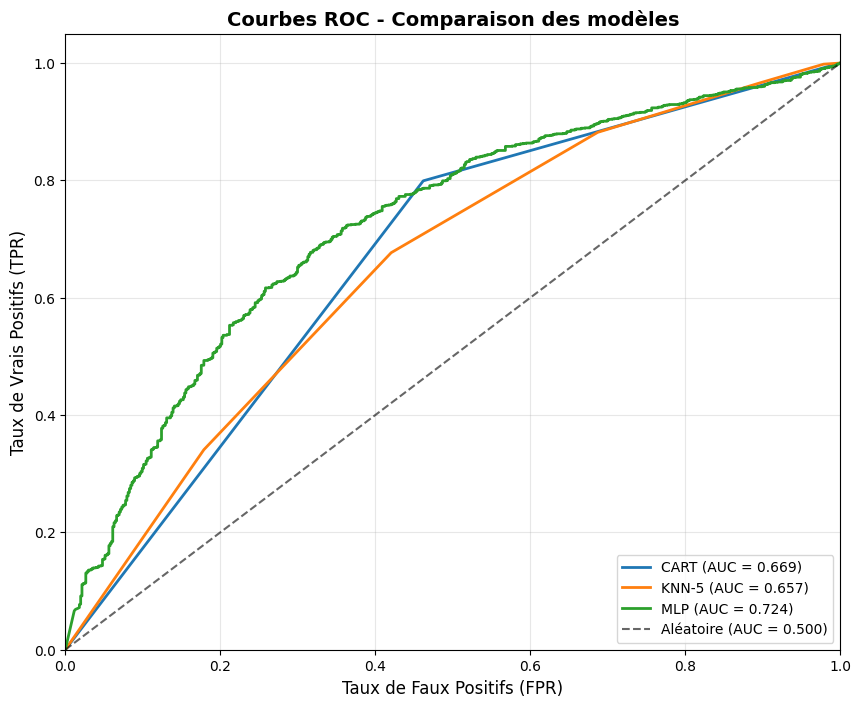


Matrices de confusion :


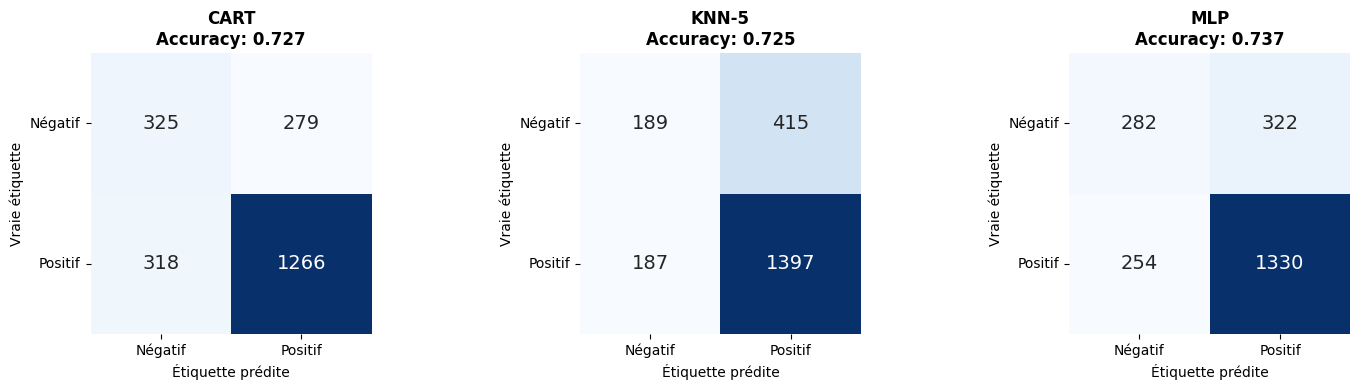


 MEILLEUR MODÈLE SÉLECTIONNÉ: KNN-5


In [95]:
# Affichage des visualisations
print("\n" + "=" * 60)
print("VISUALISATIONS")
print("=" * 60)

# Courbes ROC - Comparaison graphique des performances des modèles
print("\nCourbes ROC :")
# Affiche toutes les courbes ROC sur un même graphique
# Permet de comparer visuellement les performances des différents modèles
plot_roc_curves(all_results)

# Matrices de confusion - Analyse des erreurs de classification
print("\nMatrices de confusion :")
# Affiche les matrices de confusion pour chaque modèle côte à côte
# Montre les vrais/faux positifs et négatifs pour chaque classifieur
plot_confusion_matrices(all_results)

# Rappel du meilleur modèle identifié
print(f"\n MEILLEUR MODÈLE SÉLECTIONNÉ: {best_model_name}")

## III. Normalisation des Variables Continues

Certains algorithmes (comme le KNN et le MLP) sont sensibles à l'échelle des données. Nous allons utiliser le **StandardScaler** de Scikit-learn pour centrer et réduire les variables (moyenne = 0, écart-type = 1).

Nous comparons ensuite les résultats des modèles sur ces données normalisées par rapport aux données brutes.

In [96]:
def normalize_data(X_train, X_test, method='standard'):
    """
    Normalise les données d'entraînement et de test
    
    Parameters:
    -----------
    X_train, X_test : array-like
        Données d'entraînement et de test à normaliser
    method : str, default='standard'
        Méthode de normalisation :
        - 'standard' : StandardScaler (centrage-réduction)
        - 'minmax' : MinMaxScaler (mise à l'échelle min-max)
        
    Returns:
    --------
    X_train_normalized, X_test_normalized : array
        Données normalisées
    scaler : objet
        Scaler ajusté pour pouvoir appliquer la même transformation à de nouvelles données
    """
    # Sélection du type de normalisation
    if method == 'standard':
        scaler = StandardScaler()  # Normalisation centrée réduite (moyenne=0, écart-type=1)
    elif method == 'minmax': 
        scaler = MinMaxScaler()    # Normalisation min-max (généralement entre 0 et 1)
    else:
        # Lever une exception si la méthode n'est pas reconnue
        raise ValueError("Méthode doit être 'standard' ou 'minmax'")
    
    # Normalisation des données
    # fit_transform : calcule les paramètres (moyenne/écart-type ou min/max) sur X_train et applique la transformation
    X_train_normalized = scaler.fit_transform(X_train)
    # transform : applique la même transformation apprise sur X_train à X_test
    X_test_normalized = scaler.transform(X_test)
    
    return X_train_normalized, X_test_normalized, scaler


In [97]:

# Normalisation des données
print("NORMALISATION DES DONNÉES")
# Application de la normalisation avec StandardScaler
X_train_std, X_test_std, scaler_std = normalize_data(X_train, X_test, method='standard')

print("Données normalisées avec StandardScaler")
print(f"Shape X_train normalisé: {X_train_std.shape}")
print(f"Shape X_test normalisé: {X_test_std.shape}")

# Statistiques avant/après normalisation
print("\nCOMPARAISON AVANT/APRÈS NORMALISATION")
# Afficher les statistiques des 5 premières caractéristiques pour comparaison
print("Moyennes (avant normalisation):", np.mean(X_train, axis=0)[:5])  # 5 premières features
print("Moyennes (après normalisation):", np.mean(X_train_std, axis=0)[:5])
print("\nÉcart-types (avant normalisation):", np.std(X_train, axis=0)[:5])
print("Écart-types (après normalisation):", np.std(X_train_std, axis=0)[:5])

NORMALISATION DES DONNÉES
Données normalisées avec StandardScaler
Shape X_train normalisé: (2187, 13)
Shape X_test normalisé: (2188, 13)

COMPARAISON AVANT/APRÈS NORMALISATION
Moyennes (avant normalisation): [ 7.96844993  0.53680841 46.4170096  37.25788752  0.27343393]
Moyennes (après normalisation): [ 0.  0. -0. -0.  0.]

Écart-types (avant normalisation): [ 8.14171528  0.4986433  14.59622201 11.05319373  0.44572168]
Écart-types (après normalisation): [1. 1. 1. 1. 1.]


In [98]:
# Exécution des modèles sur données normalisées
print("=" * 70)
print("APPRENTISSAGE AVEC DONNÉES NORMALISÉES (StandardScaler)")
print("=" * 70)

# Appel de la fonction principale avec les données normalisées
best_model_std, best_model_name_std, results_std = run_classifiers_train_test(
    X_train_std, X_test_std, y_train, y_test
)

APPRENTISSAGE AVEC DONNÉES NORMALISÉES (StandardScaler)
=== APPRENTISSAGE ET ÉVALUATION DES MODÈLES ===

 CART
------------------------------
Accuracy:    0.7271
Precision:   0.8182
Recall:      0.8011
Score final: 0.7641 (Accuracy + Recall)/2
AUC:         0.6671

 KNN-5
------------------------------
Accuracy:    0.7527
Precision:   0.8106
Recall:      0.8592
Score final: 0.8060 (Accuracy + Recall)/2
AUC:         0.7539

 MLP
------------------------------
Accuracy:    0.7445
Precision:   0.8262
Recall:      0.8194
Score final: 0.7820 (Accuracy + Recall)/2
AUC:         0.7738

COMPARAISON DES MODÈLES
CART       : 0.7641
KNN-5      : 0.8060
MLP        : 0.7820

 MEILLEUR MODÈLE: KNN-5 avec un score de 0.8060


In [99]:
def compare_results_original_vs_normalized(results_original, results_normalized):
    """
    Compare les résultats avant et après normalisation
    
    Parameters:
    -----------
    results_original : dict
        Résultats des modèles sur les données originales
    results_normalized : dict
        Résultats des modèles sur les données normalisées
        
    Returns:
    --------
    comparison_data : list
        Liste de dictionnaires contenant les données de comparaison
    """
    print("=" * 80)
    print("COMPARAISON DÉTAILLÉE : ORIGINAL vs NORMALISÉ")
    print("=" * 80)
    
    comparison_data = []  # Liste pour stocker les données de comparaison
    
    # Parcourir tous les modèles qui existent dans les deux ensembles de résultats
    for model_name in results_original.keys():
        if model_name in results_normalized:
            # Extraire les métriques des résultats originaux
            orig = results_original[model_name]['metrics']
            # Extraire les métriques des résultats normalisés
            norm = results_normalized[model_name]['metrics']
            
            # Calcul des différences entre les versions normalisée et originale
            diff_accuracy = norm['accuracy'] - orig['accuracy']
            diff_recall = norm['recall'] - orig['recall']
            diff_final = norm['final_score'] - orig['final_score']
            diff_auc = norm['roc_auc'] - orig['roc_auc']
            
            # Stocker les données de comparaison dans un dictionnaire
            comparison_data.append({
                'Modèle': model_name,
                'Accuracy_orig': orig['accuracy'],
                'Accuracy_norm': norm['accuracy'],
                'Diff_accuracy': diff_accuracy,

                'Recall_orig': orig['recall'],
                'Recall_norm': norm['recall'],
                'Diff_recall': diff_recall,

                'Final_orig': orig['final_score'],
                'Final_norm': norm['final_score'],
                'Diff_final': diff_final,

                'AUC_orig': orig['roc_auc'],
                'AUC_norm': norm['roc_auc'],
                'Diff_auc': diff_auc
            })
            
            # Affichage détaillé par modèle
            print(f"\n {model_name}")
            print("-" * 40)
            # Format : valeur originale → valeur normalisée (différence)
            print(f"Accuracy:  {orig['accuracy']:.4f} → {norm['accuracy']:.4f} ({diff_accuracy:+.4f})")
            print(f"Recall:    {orig['recall']:.4f} → {norm['recall']:.4f} ({diff_recall:+.4f})")
            print(f"Score final: {orig['final_score']:.4f} → {norm['final_score']:.4f} ({diff_final:+.4f})")
            print(f"AUC:       {orig['roc_auc']:.4f} → {norm['roc_auc']:.4f} ({diff_auc:+.4f})")
            
            # Interprétation de l'impact de la normalisation
            if diff_final > 0:
                print("Amélioration avec normalisation")  # Meilleure performance
            elif diff_final < 0:
                print("Dégradation avec normalisation")   # Performance réduite
            else:
                print("Pas de changement")               # Performance identique
    
    return comparison_data

# Exécution de la comparaison entre les résultats originaux et normalisés
# all_results : résultats sur données originales
# results_std : résultats sur données normalisées (doit être défini précédemment)
comparison = compare_results_original_vs_normalized(all_results, results_std)

COMPARAISON DÉTAILLÉE : ORIGINAL vs NORMALISÉ

 CART
----------------------------------------
Accuracy:  0.7271 → 0.7271 (+0.0000)
Recall:    0.7992 → 0.8011 (+0.0019)
Score final: 0.7632 → 0.7641 (+0.0009)
AUC:       0.6687 → 0.6671 (-0.0015)
Amélioration avec normalisation

 KNN-5
----------------------------------------
Accuracy:  0.7249 → 0.7527 (+0.0279)
Recall:    0.8819 → 0.8592 (-0.0227)
Score final: 0.8034 → 0.8060 (+0.0026)
AUC:       0.6568 → 0.7539 (+0.0972)
Amélioration avec normalisation

 MLP
----------------------------------------
Accuracy:  0.7367 → 0.7445 (+0.0078)
Recall:    0.8396 → 0.8194 (-0.0202)
Score final: 0.7882 → 0.7820 (-0.0062)
AUC:       0.7242 → 0.7738 (+0.0496)
Dégradation avec normalisation


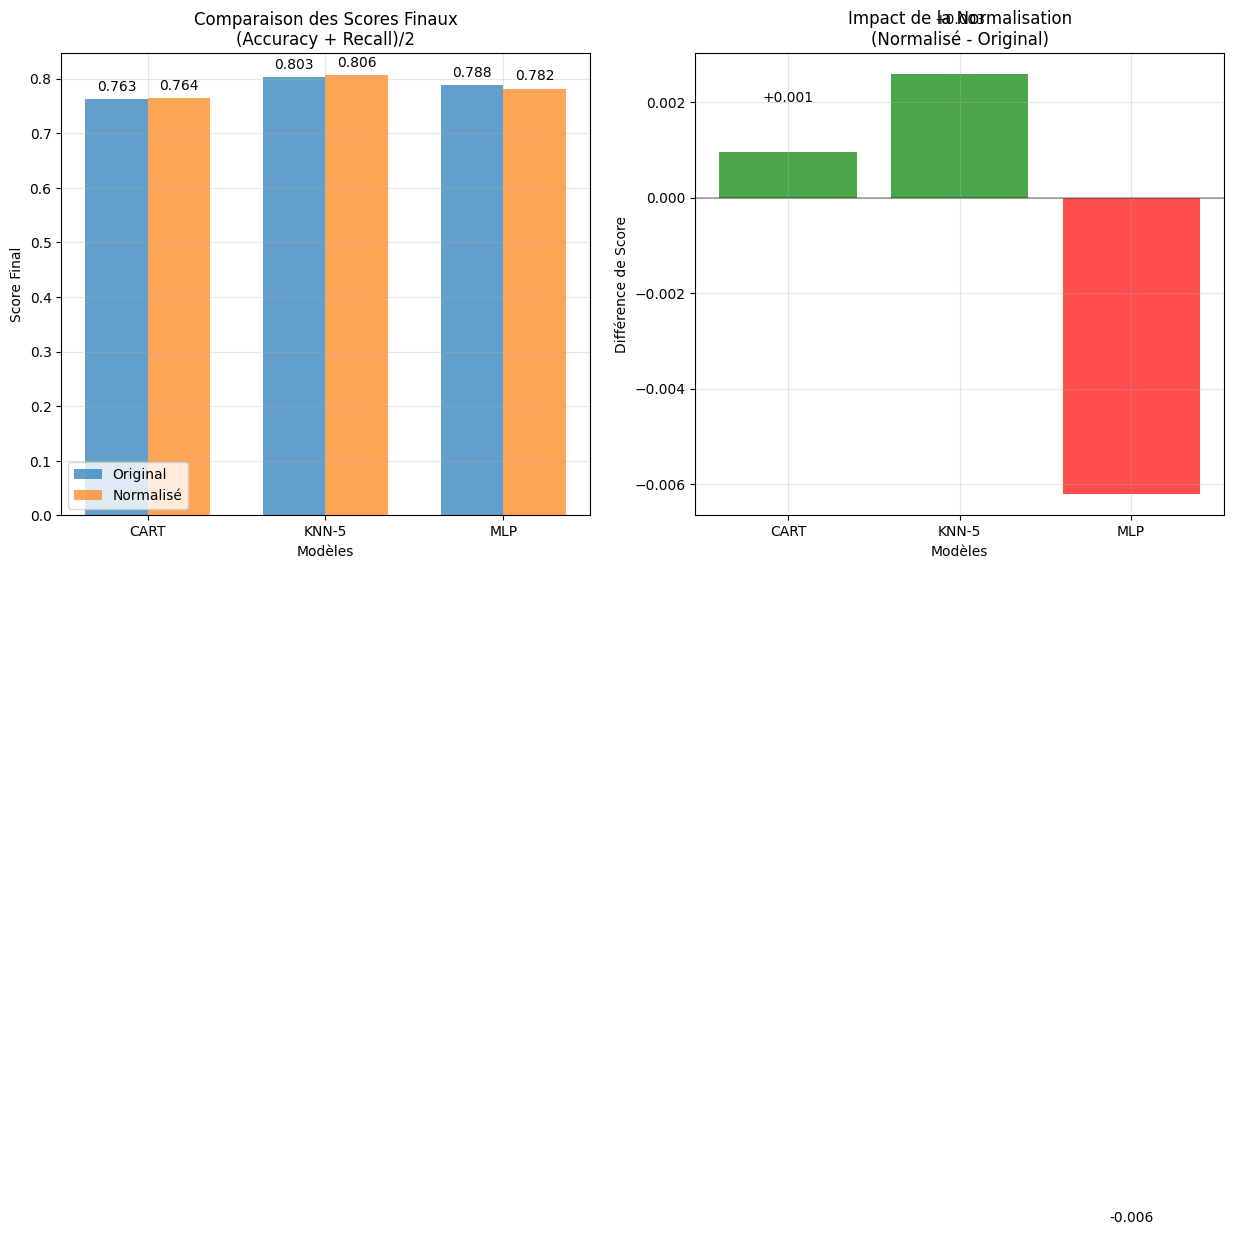

In [100]:
# Visualisation des comparaisons
def plot_comparison(comparison_data):
    """
    Visualise la comparaison avant/après normalisation
    
    Parameters:
    -----------
    comparison_data : list
        Liste de dictionnaires contenant les données de comparaison
        retournées par la fonction compare_results_original_vs_normalized
    """
    # Extraction des noms des modèles et des scores depuis les données de comparaison
    models = [item['Modèle'] for item in comparison_data]
    final_original = [item['Final_orig'] for item in comparison_data]
    final_normalized = [item['Final_norm'] for item in comparison_data]
    
    # Préparation des positions pour les barres
    x = np.arange(len(models))
    width = 0.35  # Largeur des barres
    
    # Création de la figure avec 2 sous-graphiques côte à côte
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    # Graphique 1: Scores finaux (comparaison côte à côte)
    bars1 = ax1.bar(x - width/2, final_original, width, label='Original', alpha=0.7)
    bars2 = ax1.bar(x + width/2, final_normalized, width, label='Normalisé', alpha=0.7)
    
    # Configuration du premier graphique
    ax1.set_xlabel('Modèles')
    ax1.set_ylabel('Score Final')
    ax1.set_title('Comparaison des Scores Finaux\n(Accuracy + Recall)/2')
    ax1.set_xticks(x)  # Position des ticks sur l'axe x
    ax1.set_xticklabels(models)  # Étiquettes des ticks = noms des modèles
    ax1.legend()  # Ajout de la légende
    ax1.grid(True, alpha=0.3)  # Grille avec transparence
    
    # Ajouter les valeurs numériques sur les barres (version originale)
    for bar in bars1:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.3f}', ha='center', va='bottom')
    
    # Ajouter les valeurs numériques sur les barres (version normalisée)
    for bar in bars2:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.3f}', ha='center', va='bottom')
    
    # Graphique 2: Différences de performance
    differences = [item['Diff_final'] for item in comparison_data]
    # Choix des couleurs : vert pour amélioration, rouge pour dégradation
    colors = ['green' if diff > 0 else 'red' for diff in differences]
    
    bars = ax2.bar(models, differences, color=colors, alpha=0.7)
    ax2.set_xlabel('Modèles')
    ax2.set_ylabel('Différence de Score')
    ax2.set_title('Impact de la Normalisation\n(Normalisé - Original)')
    ax2.axhline(y=0, color='black', linestyle='-', alpha=0.3)  # Ligne de référence à y=0
    ax2.grid(True, alpha=0.3)
    
    # Ajouter les valeurs numériques sur les barres des différences
    for bar, diff in zip(bars, differences):
        height = bar.get_height()
        # Positionnement différent selon le signe de la différence
        if height >= 0:
            ax2.text(bar.get_x() + bar.get_width()/2., height + 0.001,
                    f'{height:+.3f}', ha='center', va='bottom')
        else:
            ax2.text(bar.get_x() + bar.get_width()/2., height - 0.015,
                    f'{height:+.3f}', ha='center', va='top')
    
    # Ajuster l'espacement pour éviter les chevauchements
    plt.tight_layout()
    plt.show()

# Affichage de la visualisation
plot_comparison(comparison)

## IV. Création de Nouvelles Variables (ACP)

Nous utilisons l'**Analyse en Composantes Principales (ACP)** pour créer de nouvelles variables par combinaison linéaire des variables initiales. Ces nouvelles composantes sont concaténées aux données existantes pour tenter d'améliorer la séparabilité des classes.

In [101]:
def apply_pca_and_concat(X_train, X_test, n_components=3):
    """
    Applique l'ACP et concatène les composantes aux données originales
    
    Parameters:
    -----------
    X_train, X_test : array-like
        Données d'entraînement et de test
    n_components : int, default=3
        Nombre de composantes principales à extraire
        
    Returns:
    --------
    X_train_combined, X_test_combined : array
        Données originales concaténées avec les composantes ACP
    pca : objet PCA
        Modèle ACP ajusté
    X_train_pca, X_test_pca : array
        Composantes principales extraites séparément
    """
    # Application de l'ACP (Analyse en Composantes Principales)
    pca = PCA(n_components=n_components, random_state=1)  # random_state pour reproductibilité
    
    # Transformation des données : apprentissage sur train, application sur train et test
    X_train_pca = pca.fit_transform(X_train)  # Calcul des composantes sur train
    X_test_pca = pca.transform(X_test)        # Application de la même transformation sur test
    
    # Concaténation des données originales avec les composantes ACP
    # axis=1 signifie concaténation par colonnes (ajout de nouvelles caractéristiques)
    X_train_combined = np.concatenate([X_train, X_train_pca], axis=1)
    X_test_combined = np.concatenate([X_test, X_test_pca], axis=1)
    
    return X_train_combined, X_test_combined, pca, X_train_pca, X_test_pca

print("APPLICATION DE L'ACP")
# Application sur les données normalisées avec 3 composantes principales
X_train_pca_combined, X_test_pca_combined, pca, X_train_pca, X_test_pca = apply_pca_and_concat(
    X_train_std, X_test_std, n_components=3
)

print(f"Shape données originales: {X_train_std.shape}")
print(f"Shape composantes ACP: {X_train_pca.shape}")
print(f"Shape données combinées: {X_train_pca_combined.shape}")

# Analyse de l'ACP : comprendre ce que les composantes capturent
print(f"\nANALYSE DE L'ACP")
# Variance expliquée : proportion d'information conservée par chaque composante
print(f"Variance expliquée par chaque composante: {pca.explained_variance_ratio_}")
# Variance cumulative : somme cumulative de la variance expliquée
print(f"Variance cumulative: {np.cumsum(pca.explained_variance_ratio_)}")
# Total de variance expliquée par les n composantes sélectionnées
print(f"Total variance expliquée: {np.sum(pca.explained_variance_ratio_):.3f}")

APPLICATION DE L'ACP
Shape données originales: (2187, 13)
Shape composantes ACP: (2187, 3)
Shape données combinées: (2187, 16)

ANALYSE DE L'ACP
Variance expliquée par chaque composante: [0.18820572 0.14667046 0.10648009]
Variance cumulative: [0.18820572 0.33487618 0.44135627]
Total variance expliquée: 0.441


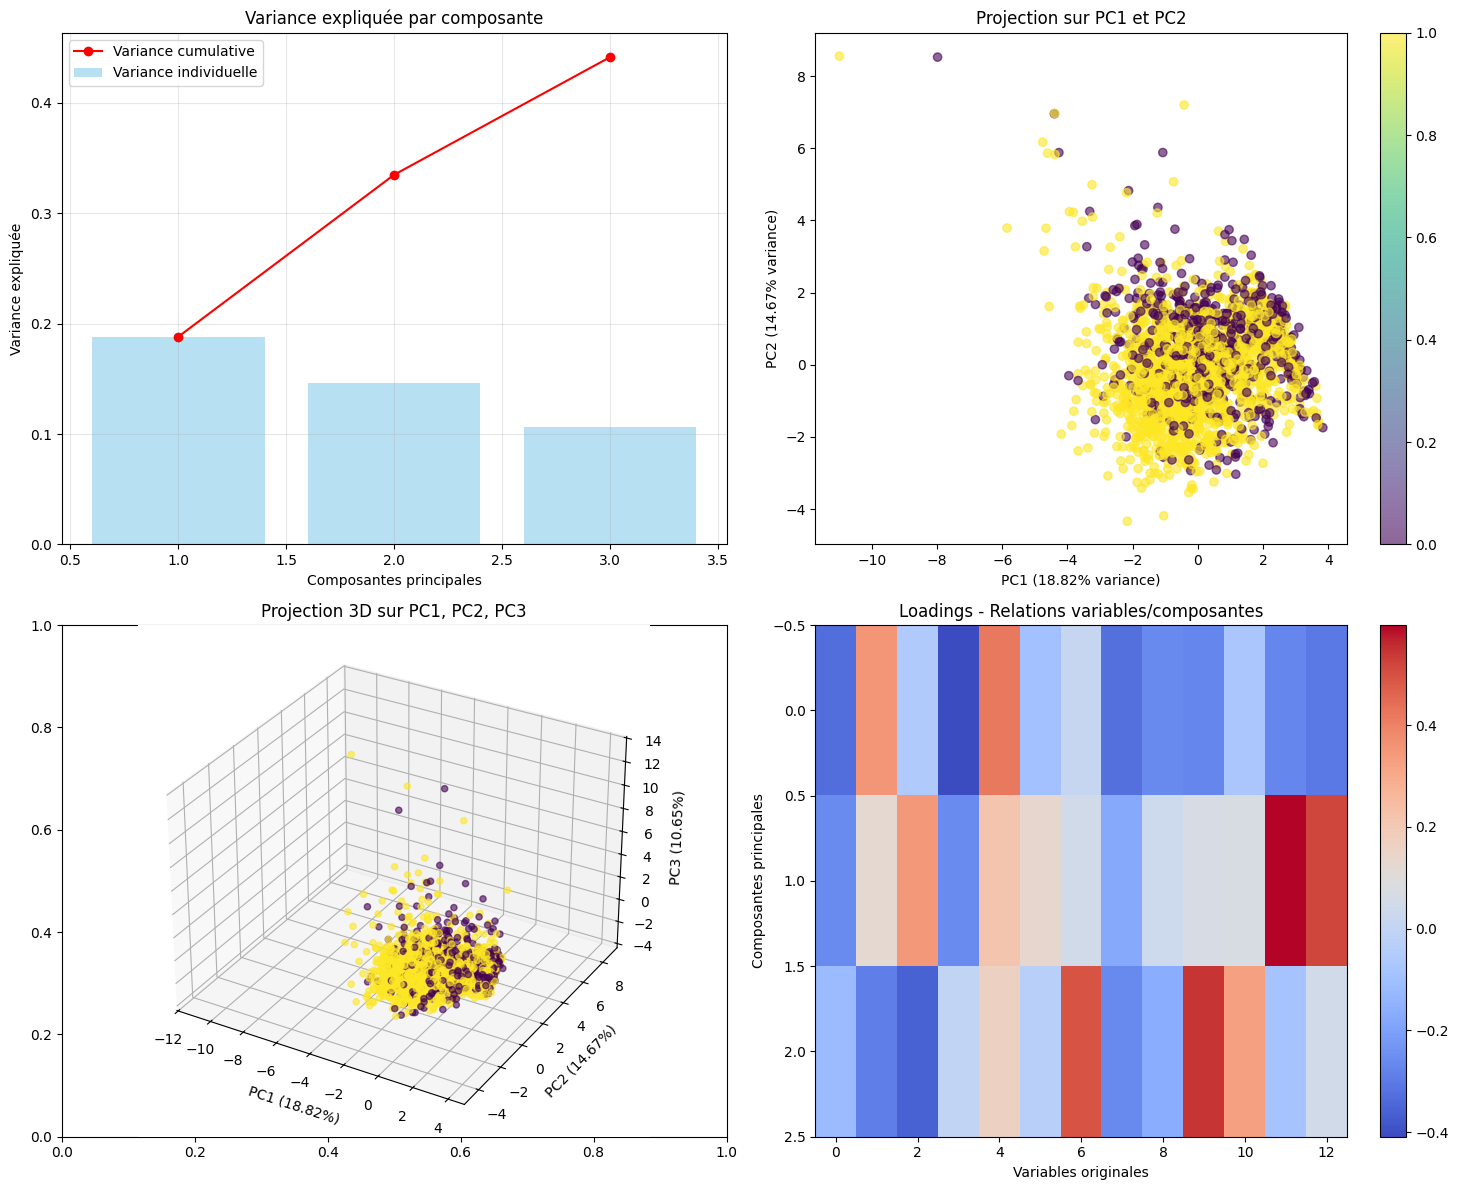

In [102]:
def plot_pca_analysis(pca, X_train_pca, y_train):
    """
    Visualise les résultats de l'ACP
    
    Parameters:
    -----------
    pca : objet PCA
        Modèle ACP ajusté
    X_train_pca : array
        Composantes principales des données d'entraînement
    y_train : array
        Étiquettes des données d'entraînement (pour la coloration)
    """
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    
    # 1. Variance expliquée - Graphique à barres et courbe cumulative
    explained_variance = pca.explained_variance_ratio_  # Variance expliquée par chaque composante
    cumulative_variance = np.cumsum(explained_variance)  # Variance cumulative
    
    # Barres pour la variance individuelle de chaque composante
    axes[0, 0].bar(range(1, len(explained_variance) + 1), explained_variance, 
                  alpha=0.6, color='skyblue', label='Variance individuelle')
    # Courbe pour la variance cumulative
    axes[0, 0].plot(range(1, len(cumulative_variance) + 1), cumulative_variance, 
                   'ro-', label='Variance cumulative')
    axes[0, 0].set_xlabel('Composantes principales')
    axes[0, 0].set_ylabel('Variance expliquée')
    axes[0, 0].set_title('Variance expliquée par composante')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # 2. Projection sur les 2 premières composantes principales
    # Nuage de points coloré par les étiquettes y_train
    scatter = axes[0, 1].scatter(X_train_pca[:, 0], X_train_pca[:, 1], 
                                c=y_train, cmap='viridis', alpha=0.6)
    axes[0, 1].set_xlabel(f'PC1 ({explained_variance[0]:.2%} variance)')  # % de variance expliquée
    axes[0, 1].set_ylabel(f'PC2 ({explained_variance[1]:.2%} variance)')
    axes[0, 1].set_title('Projection sur PC1 et PC2')
    plt.colorbar(scatter, ax=axes[0, 1])  # Barre de couleur pour les étiquettes
    
    # 3. Projection 3D (si au moins 3 composantes)
    if X_train_pca.shape[1] >= 3:
        # Création d'un subplot 3D
        ax3d = fig.add_subplot(2, 2, 3, projection='3d')
        scatter3d = ax3d.scatter(X_train_pca[:, 0], X_train_pca[:, 1], X_train_pca[:, 2], 
                                c=y_train, cmap='viridis', alpha=0.6)
        ax3d.set_xlabel(f'PC1 ({explained_variance[0]:.2%})')
        ax3d.set_ylabel(f'PC2 ({explained_variance[1]:.2%})')
        ax3d.set_zlabel(f'PC3 ({explained_variance[2]:.2%})')
        ax3d.set_title('Projection 3D sur PC1, PC2, PC3')
    else:
        # Si moins de 3 composantes, on laisse cette case vide
        axes[1, 0].axis('off')
    
    # 4. Heatmap des loadings (corrélations entre variables originales et composantes)
    if hasattr(pca, 'components_'):
        # pca.components_ contient les vecteurs propres (loadings)
        im = axes[1, 1].imshow(pca.components_[:3, :], cmap='coolwarm', aspect='auto')
        axes[1, 1].set_xlabel('Variables originales')
        axes[1, 1].set_ylabel('Composantes principales')
        axes[1, 1].set_title('Loadings - Relations variables/composantes')
        plt.colorbar(im, ax=axes[1, 1])  # Barre de couleur pour les valeurs des loadings
    
    plt.tight_layout()  # Ajustement automatique de l'espacement
    plt.show()

# Visualisation des résultats de l'ACP
plot_pca_analysis(pca, X_train_pca, y_train)

In [103]:
# Exécution des modèles sur données avec ACP
print("=" * 80)
print("APPRENTISSAGE AVEC DONNÉES NORMALISÉES + ACP")
print("=" * 80)

# Exécution des classifieurs sur les données enrichies par ACP
# X_train_pca_combined : données normalisées concaténées avec les composantes ACP
# X_test_pca_combined : données de test traitées de la même manière
# y_train, y_test : étiquettes d'entraînement et de test (inchangées)

best_model_pca, best_model_name_pca, results_pca = run_classifiers_train_test(
    X_train_pca_combined, X_test_pca_combined, y_train, y_test
)

# La fonction retourne :
# best_model_pca : meilleur modèle identifié sur les données avec ACP
# best_model_name_pca : nom du meilleur modèle avec ACP
# results_pca : dictionnaire contenant tous les résultats d'évaluation avec ACP

APPRENTISSAGE AVEC DONNÉES NORMALISÉES + ACP
=== APPRENTISSAGE ET ÉVALUATION DES MODÈLES ===

 CART
------------------------------
Accuracy:    0.7258
Precision:   0.8233
Recall:      0.7910
Score final: 0.7584 (Accuracy + Recall)/2
AUC:         0.6728

 KNN-5
------------------------------
Accuracy:    0.7564
Precision:   0.8104
Recall:      0.8662
Score final: 0.8113 (Accuracy + Recall)/2
AUC:         0.7555

 MLP
------------------------------
Accuracy:    0.7500
Precision:   0.8222
Recall:      0.8352
Score final: 0.7926 (Accuracy + Recall)/2
AUC:         0.7745

COMPARAISON DES MODÈLES
CART       : 0.7584
KNN-5      : 0.8113
MLP        : 0.7926

 MEILLEUR MODÈLE: KNN-5 avec un score de 0.8113


### Comparaison des performances des modèles avec et sans ACP

In [104]:
def comprehensive_comparison(all_strategies):
    """
    Compare toutes les stratégies de préparation des données
    
    Parameters:
    -----------
    all_strategies : dict
        Dictionnaire contenant les résultats pour chaque stratégie de prétraitement
        
    Returns:
    --------
    pd.DataFrame : DataFrame pandas contenant le tableau comparatif complet
    """
    print("=" * 100)
    print("COMPARAISON COMPLÈTE DES STRATÉGIES DE PRÉPARATION DES DONNÉES")
    print("=" * 100)
    
    # Extraction des noms des stratégies et des modèles
    strategies = list(all_strategies.keys())  # Ex: ['Original', 'Normalisé', 'Normalisé + ACP']
    models = list(all_strategies[strategies[0]].keys())  # Noms des modèles à partir de la première stratégie
    
    # Tableau de comparaison (liste de dictionnaires)
    comparison_table = []
    
    # Parcours de chaque stratégie de prétraitement
    for strategy in strategies:
        print(f"\nSTRATÉGIE: {strategy}")
        print("-" * 50)
        
        # Parcours de chaque modèle dans la stratégie courante
        for model in models:
            # Vérification que le modèle existe dans cette stratégie
            if model in all_strategies[strategy]:
                metrics = all_strategies[strategy][model]['metrics']
                
                # Ajout des données au tableau de comparaison
                comparison_table.append({
                    'Stratégie': strategy,
                    'Modèle': model,
                    'Accuracy': metrics['accuracy'],
                    'Recall': metrics['recall'],
                    'Final_Score': metrics['final_score'],
                    'AUC': metrics['roc_auc']
                })
                
                # Affichage formaté des résultats pour ce modèle
                print(f"{model:8} | Accuracy: {metrics['accuracy']:.4f} | Recall: {metrics['recall']:.4f} | "
                      f"Final: {metrics['final_score']:.4f} | AUC: {metrics['roc_auc']:.4f}")
    
    # Conversion en DataFrame pandas pour une analyse plus facile
    return pd.DataFrame(comparison_table)

# Collecte de toutes les stratégies testées dans un dictionnaire unique
all_strategies = {
    'Original': all_results,           # Données originales (sans prétraitement)
    'Normalisé': results_std,          # Données normalisées avec StandardScaler
    'Normalisé + ACP': results_pca     # Données normalisées + composantes ACP
}

# Exécution de la comparaison complète
comparison_df = comprehensive_comparison(all_strategies)

COMPARAISON COMPLÈTE DES STRATÉGIES DE PRÉPARATION DES DONNÉES

STRATÉGIE: Original
--------------------------------------------------
CART     | Accuracy: 0.7271 | Recall: 0.7992 | Final: 0.7632 | AUC: 0.6687
KNN-5    | Accuracy: 0.7249 | Recall: 0.8819 | Final: 0.8034 | AUC: 0.6568
MLP      | Accuracy: 0.7367 | Recall: 0.8396 | Final: 0.7882 | AUC: 0.7242

STRATÉGIE: Normalisé
--------------------------------------------------
CART     | Accuracy: 0.7271 | Recall: 0.8011 | Final: 0.7641 | AUC: 0.6671
KNN-5    | Accuracy: 0.7527 | Recall: 0.8592 | Final: 0.8060 | AUC: 0.7539
MLP      | Accuracy: 0.7445 | Recall: 0.8194 | Final: 0.7820 | AUC: 0.7738

STRATÉGIE: Normalisé + ACP
--------------------------------------------------
CART     | Accuracy: 0.7258 | Recall: 0.7910 | Final: 0.7584 | AUC: 0.6728
KNN-5    | Accuracy: 0.7564 | Recall: 0.8662 | Final: 0.8113 | AUC: 0.7555
MLP      | Accuracy: 0.7500 | Recall: 0.8352 | Final: 0.7926 | AUC: 0.7745


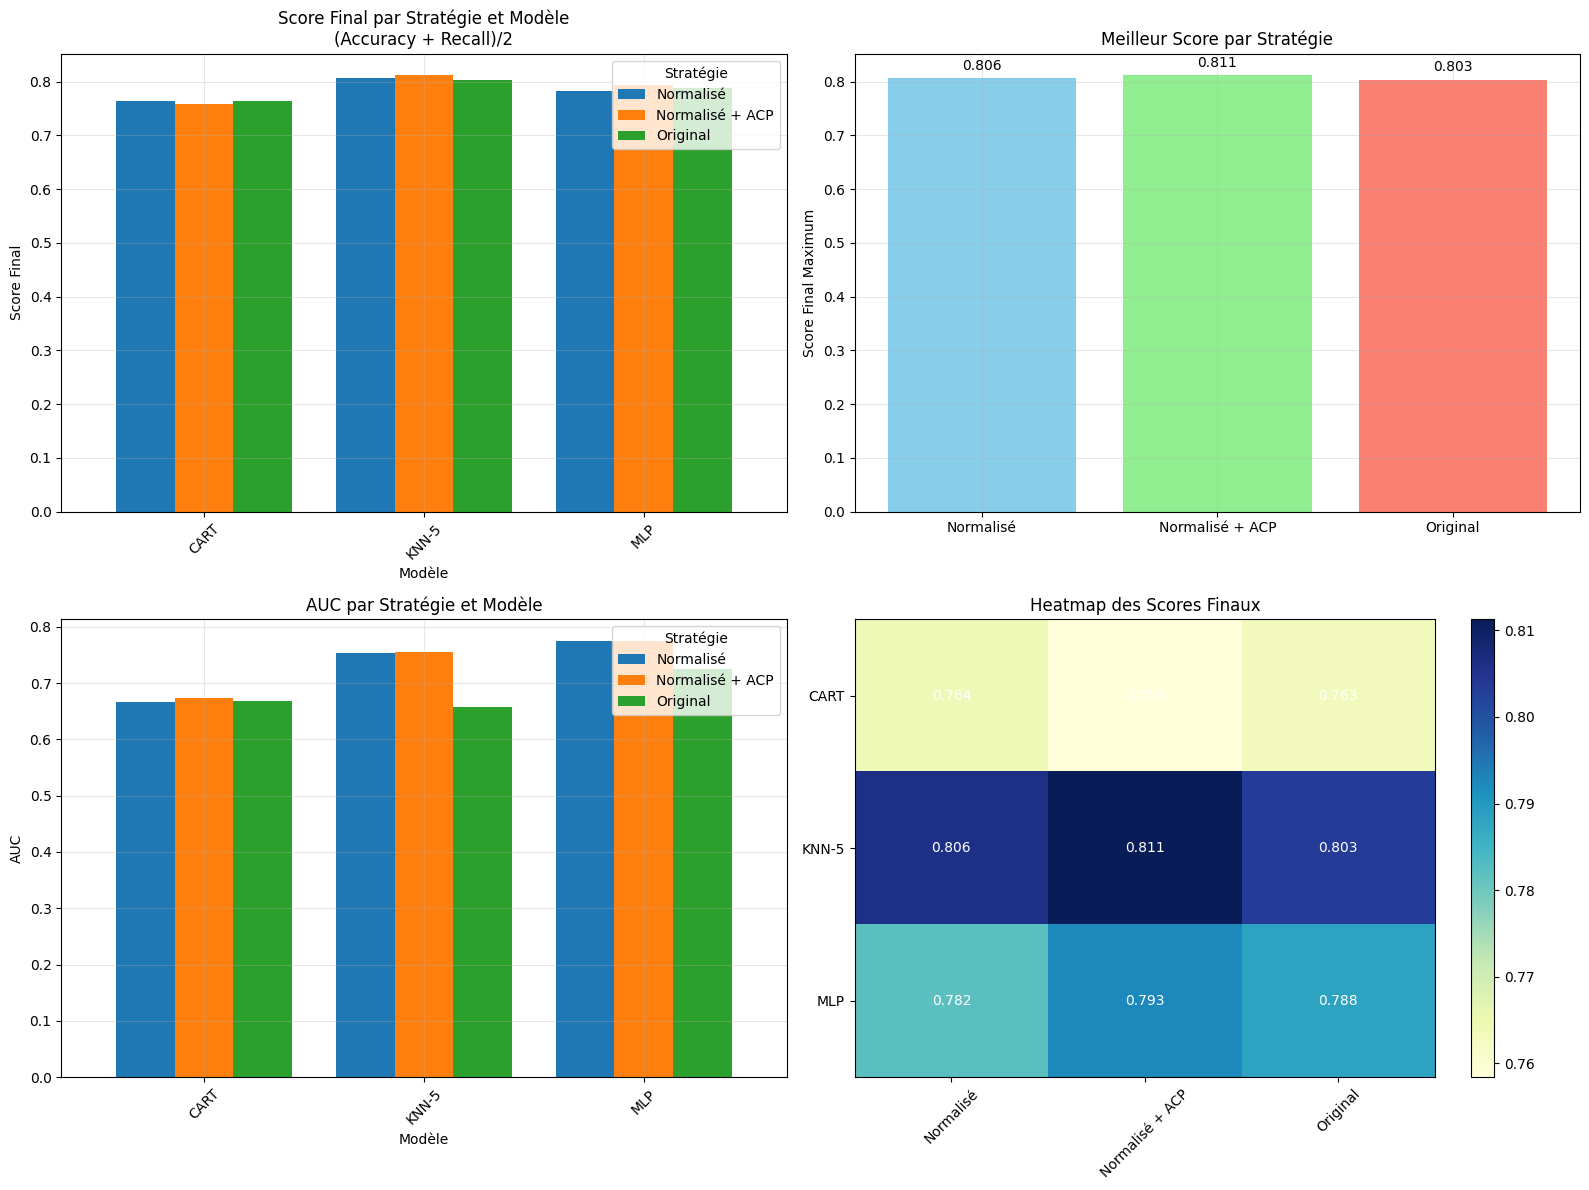

In [105]:
def plot_global_comparison(comparison_df):
    """
    Visualise la comparaison globale des stratégies
    
    Parameters:
    -----------
    comparison_df : pd.DataFrame
        DataFrame contenant les résultats de comparaison des différentes stratégies
    """
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    # 1. Scores finaux par stratégie et modèle (graphique à barres groupées)
    # Pivot du DataFrame pour avoir les stratégies en colonnes et les modèles en lignes
    pivot_final = comparison_df.pivot(index='Modèle', columns='Stratégie', values='Final_Score')
    pivot_final.plot(kind='bar', ax=axes[0, 0], width=0.8)
    axes[0, 0].set_title('Score Final par Stratégie et Modèle\n(Accuracy + Recall)/2')
    axes[0, 0].set_ylabel('Score Final')
    axes[0, 0].legend(title='Stratégie')
    axes[0, 0].tick_params(axis='x', rotation=45)  # Rotation des étiquettes pour lisibilité
    axes[0, 0].grid(True, alpha=0.3)
    
    # 2. Meilleur score par stratégie (graphique à barres simples)
    # Trouve le meilleur score final pour chaque stratégie
    best_by_strategy = comparison_df.groupby('Stratégie')['Final_Score'].max()
    axes[0, 1].bar(best_by_strategy.index, best_by_strategy.values, 
                   color=['skyblue', 'lightgreen', 'salmon'])  # Couleurs différentes
    axes[0, 1].set_title('Meilleur Score par Stratégie')
    axes[0, 1].set_ylabel('Score Final Maximum')
    # Ajout des valeurs numériques sur les barres
    for i, v in enumerate(best_by_strategy.values):
        axes[0, 1].text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom')
    axes[0, 1].grid(True, alpha=0.3)
    
    # 3. AUC par stratégie et modèle (graphique à barres groupées)
    pivot_auc = comparison_df.pivot(index='Modèle', columns='Stratégie', values='AUC')
    pivot_auc.plot(kind='bar', ax=axes[1, 0], width=0.8)
    axes[1, 0].set_title('AUC par Stratégie et Modèle')
    axes[1, 0].set_ylabel('AUC')
    axes[1, 0].legend(title='Stratégie')
    axes[1, 0].tick_params(axis='x', rotation=45)
    axes[1, 0].grid(True, alpha=0.3)
    
    # 4. Heatmap des performances (visualisation matricielle)
    heatmap_data = comparison_df.pivot(index='Modèle', columns='Stratégie', values='Final_Score')
    im = axes[1, 1].imshow(heatmap_data.values, cmap='YlGnBu', aspect='auto')  # Carte de couleur bleue
    axes[1, 1].set_xticks(range(len(heatmap_data.columns)))
    axes[1, 1].set_xticklabels(heatmap_data.columns, rotation=45)
    axes[1, 1].set_yticks(range(len(heatmap_data.index)))
    axes[1, 1].set_yticklabels(heatmap_data.index)
    axes[1, 1].set_title('Heatmap des Scores Finaux')
    
    # Ajouter les valeurs numériques dans chaque cellule de la heatmap
    for i in range(len(heatmap_data.index)):
        for j in range(len(heatmap_data.columns)):
            # Choix de la couleur du texte selon la valeur de la cellule
            text_color = 'black' if heatmap_data.iloc[i, j] < 0.7 else 'white'
            axes[1, 1].text(j, i, f'{heatmap_data.iloc[i, j]:.3f}', 
                           ha='center', va='center', color=text_color)
    
    # Barre de couleur pour la heatmap
    plt.colorbar(im, ax=axes[1, 1])
    plt.tight_layout()  # Ajustement automatique de l'espacement
    plt.show()

# Affichage de la comparaison globale
plot_global_comparison(comparison_df)

In [106]:
print("=" * 100)
print("CONCLUSIONS ET RECOMMANDATIONS FINALES")
print("=" * 100)

# Meilleur modèle global
# Trouve la ligne avec le score final le plus élevé dans le DataFrame de comparaison
best_overall = comparison_df.loc[comparison_df['Final_Score'].idxmax()]
print(f"\nMEILLEUR RÉSULTAT GLOBAL:")
print(f"  Modèle: {best_overall['Modèle']}")
print(f"  Stratégie: {best_overall['Stratégie']}")
print(f"  Score final: {best_overall['Final_Score']:.4f}")
print(f"  AUC: {best_overall['AUC']:.4f}")

# Analyse par stratégie
print(f"\nANALYSE PAR STRATÉGIE:")

for strategy in all_strategies.keys():
    # Filtrer le DataFrame pour la stratégie courante
    strategy_scores = comparison_df[comparison_df['Stratégie'] == strategy]['Final_Score']
    
    # Trouver le meilleur modèle pour cette stratégie
    best_model_strategy = comparison_df[comparison_df['Stratégie'] == strategy].loc[
        comparison_df[comparison_df['Stratégie'] == strategy]['Final_Score'].idxmax()
    ]
    
    # Afficher les statistiques pour cette stratégie
    print(f"\n{strategy}:")
    print(f"  Score moyen: {strategy_scores.mean():.4f}")
    print(f"  Meilleur modèle: {best_model_strategy['Modèle']} ({best_model_strategy['Final_Score']:.4f})")
    print(f"  Écart-type: {strategy_scores.std():.4f}")

# Recommandations basées sur les résultats
print(f"\nRECOMMANDATIONS POUR LA SUITE:")
print(f"1. MEILLEUR ALGORITHME: {best_overall['Modèle']}")
print(f"2. MEILLEURE STRATÉGIE: {best_overall['Stratégie']}")

# Décision sur la normalisation
# Calcul des scores moyens pour les stratégies originales et normalisées
original_mean = comparison_df[comparison_df['Stratégie'] == 'Original']['Final_Score'].mean()
normalized_mean = comparison_df[comparison_df['Stratégie'] == 'Normalisé']['Final_Score'].mean()

# Recommandation basée sur la comparaison des moyennes
if normalized_mean > original_mean:
    print("3. NORMALISATION: RECOMMANDÉE (améliore les performances)")
else:
    print("3. NORMALISATION: NON NÉCESSAIRE (pas d'amélioration significative)")

# Décision sur l'ACP
# Calcul du score moyen pour la stratégie ACP
pca_mean = comparison_df[comparison_df['Stratégie'] == 'Normalisé + ACP']['Final_Score'].mean()

# Recommandation basée sur la comparaison avec les autres stratégies
if pca_mean > normalized_mean and pca_mean > original_mean:
    print("4. ACP: RECOMMANDÉE (apporte une valeur ajoutée)")
else:
    print("4. ACP: NON NÉCESSAIRE (pas d'amélioration significative)")

# Conclusion finale
print(f"\nSTRATÉGIE FINALE CHOISIE: {best_overall['Stratégie']} avec {best_overall['Modèle']}")

CONCLUSIONS ET RECOMMANDATIONS FINALES

MEILLEUR RÉSULTAT GLOBAL:
  Modèle: KNN-5
  Stratégie: Normalisé + ACP
  Score final: 0.8113
  AUC: 0.7555

ANALYSE PAR STRATÉGIE:

Original:
  Score moyen: 0.7849
  Meilleur modèle: KNN-5 (0.8034)
  Écart-type: 0.0203

Normalisé:
  Score moyen: 0.7840
  Meilleur modèle: KNN-5 (0.8060)
  Écart-type: 0.0210

Normalisé + ACP:
  Score moyen: 0.7874
  Meilleur modèle: KNN-5 (0.8113)
  Écart-type: 0.0268

RECOMMANDATIONS POUR LA SUITE:
1. MEILLEUR ALGORITHME: KNN-5
2. MEILLEURE STRATÉGIE: Normalisé + ACP
3. NORMALISATION: NON NÉCESSAIRE (pas d'amélioration significative)
4. ACP: RECOMMANDÉE (apporte une valeur ajoutée)

STRATÉGIE FINALE CHOISIE: Normalisé + ACP avec KNN-5


## V. Sélection de Variables (Feature Importance)

Pour identifier les variables les plus pertinentes pour la prédiction, nous utilisons un **Random Forest**. Cela nous permet d'afficher l'histogramme des importances des variables et de sélectionner celles qui contribuent le plus au modèle.

### Première fonction – Importance des variables

In [107]:
from sklearn.ensemble import RandomForestClassifier

In [108]:
# Entraînement d'une forêt aléatoire pour obtenir l'importance des variables
clf = RandomForestClassifier(n_estimators=100, random_state=1)

# Apprentissage sur les données d'entraînement (X_train, y_train)
clf.fit(X_train, y_train)

# Importance moyenne des caractéristiques calculée par la forêt
# (chaque arbre fournit des importances; la forêt renvoie la moyenne)
importances = clf.feature_importances_

# Écart-type des importances entre les arbres de la forêt
# Permet d'évaluer la variabilité (incertitude) de l'importance pour chaque feature
std = np.std([tree.feature_importances_ for tree in clf.estimators_], axis=0)

# Indices des caractéristiques triés par importance décroissante
sorted_idx = np.argsort(importances)[::-1]

In [109]:
def plot_feature_importance(X_train, y_train, feature_names=None):
    """
    Calcule et affiche l'importance des variables avec Random Forest
    
    Parameters:
    -----------
    X_train : array-like
        Caractéristiques d'entraînement
    y_train : array-like
        Étiquettes d'entraînement
    feature_names : list, str or None
        Noms des variables. Peut être:
        - None : utilisation de noms génériques "Feature_i"
        - str : chaîne séparée par des points-virgules
        - list : liste de noms
        
    Returns:
    --------
    importances : array
        Importance de chaque variable
    sorted_idx : array
        Indices des variables triées par importance décroissante
    feature_names : array
        Noms des variables (potentiellement ajustés)
    """
    # Gestion des noms de variables
    if feature_names is None:
        # Création de noms génériques si aucun nom n'est fourni
        feature_names = [f"Feature_{i}" for i in range(X_train.shape[1])]
    elif isinstance(feature_names, str):
        # Si une chaîne est fournie, la diviser par points-virgules
        feature_names = feature_names.split(";")
    
    # Vérification de la cohérence entre le nombre de variables et le nombre de noms
    n_features = X_train.shape[1]
    if len(feature_names) != n_features:
        print(f"Attention: {len(feature_names)} noms fournis pour {n_features} variables")
        print("Utilisation des premiers noms disponibles...")
        feature_names = feature_names[:n_features]  # Troncature si trop de noms
    
    feature_names = np.array(feature_names)  # Conversion en tableau numpy
    
    # Création et entraînement d'un Random Forest pour l'analyse d'importance
    clf = RandomForestClassifier(n_estimators=1000, random_state=1)  # 1000 arbres pour stabilité
    clf.fit(X_train, y_train)
    
    # Extraction des importances et de leur écart-type
    importances = clf.feature_importances_  # Importance moyenne de chaque variable
    std = np.std([tree.feature_importances_ for tree in clf.estimators_], axis=0)  # Variabilité
    sorted_idx = np.argsort(importances)[::-1]  # Indices triés par importance décroissante
    
    print("Variables triées par importance: \n", feature_names[sorted_idx])
    
    print("="*60)
    print("IMPORTANCE DES VARIABLES")
    print("="*60)
    print("\nClassement des variables par importance:")
    # Affichage détaillé du classement
    for i, idx in enumerate(sorted_idx):
        print(f"{i+1:2d}. {feature_names[idx]:15}: {importances[idx]:.4f} (+/- {std[idx]:.4f})")
    
    # Visualisation graphique
    plt.figure(figsize=(12, 8))
    padding = np.arange(n_features) + 0.5  # Positionnement vertical des barres
    
    # Graphique à barres horizontales avec barres d'erreur
    plt.barh(padding, importances[sorted_idx], xerr=std[sorted_idx], align='center', alpha=0.7)
    plt.yticks(padding, feature_names[sorted_idx])  # Noms des variables sur l'axe Y
    plt.xlabel("Importance Relative", fontsize=12)
    plt.ylabel("Variables", fontsize=12)
    plt.title("Importance des Variables (Random Forest)", fontsize=14, fontweight='bold')
    plt.grid(True, alpha=0.3, axis='x')  # Grille uniquement sur l'axe X
    plt.tight_layout()  # Ajustement automatique
    plt.show()
    
    return importances, sorted_idx, feature_names

=== ANALYSE DE LA STRUCTURE DES DONNÉES ===
Shape de X_train: (2187, 13)
Shape de X_test: (2188, 13)
Colonnes du DataFrame original: ['Seniority', 'Home', 'Time', 'Age', 'Marital', 'Records', 'Job', 'Expenses', 'Income', 'Assets', 'Debt', 'Amount', 'Price', 'Status']
Nombre de noms de features: 14
Attention: 14 noms fournis pour 13 variables
Utilisation des premiers noms disponibles...
Variables triées par importance: 
 ['Income' 'Seniority' 'Price' 'Amount' 'Age' 'Assets' 'Expenses' 'Records'
 'Time' 'Job' 'Debt' 'Home' 'Marital']
IMPORTANCE DES VARIABLES

Classement des variables par importance:
 1. Income         : 0.1481 (+/- 0.0228)
 2. Seniority      : 0.1302 (+/- 0.0230)
 3. Price          : 0.1227 (+/- 0.0185)
 4. Amount         : 0.1169 (+/- 0.0171)
 5. Age            : 0.1023 (+/- 0.0167)
 6. Assets         : 0.0828 (+/- 0.0158)
 7. Expenses       : 0.0736 (+/- 0.0130)
 8. Records        : 0.0662 (+/- 0.0159)
 9. Time           : 0.0471 (+/- 0.0101)
10. Job            : 0.041

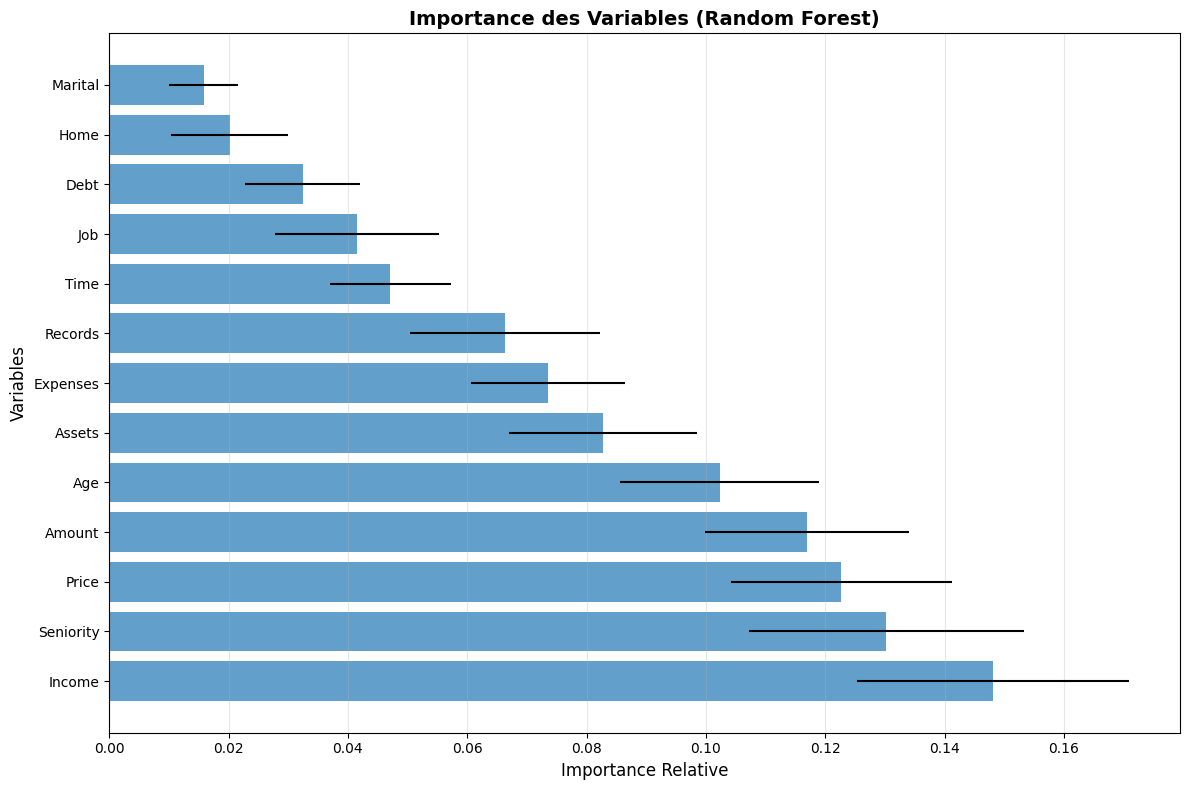

In [110]:
print("=== ANALYSE DE LA STRUCTURE DES DONNÉES ===")
# Affichage des dimensions des ensembles d'entraînement et de test
print(f"Shape de X_train: {X_train.shape}")
print(f"Shape de X_test: {X_test.shape}")

# Affichage des noms des colonnes du DataFrame original
print(f"Colonnes du DataFrame original: {df.columns.tolist()}")

# Extraction des noms de caractéristiques depuis les colonnes du DataFrame
feature_names = df.columns.tolist()  # Liste de tous les noms de colonnes

# Correction éventuelle des noms de caractéristiques (copie pour éviter les modifications)
feature_names_corrected = df.columns.tolist()
print(f"Nombre de noms de features: {len(feature_names_corrected)}")

# Appel de la fonction d'analyse d'importance des variables
importances, sorted_idx, feature_names = plot_feature_importance(
    X_train, y_train, 
    feature_names=feature_names_corrected  # Passage des noms des colonnes
)

# La fonction retourne :
# - importances : tableau des importances de chaque variable
# - sorted_idx : indices des variables triées par importance décroissante
# - feature_names : noms des variables (potentiellement ajustés)

### Deuxième fonction – Sélection du nombre optimal de variables

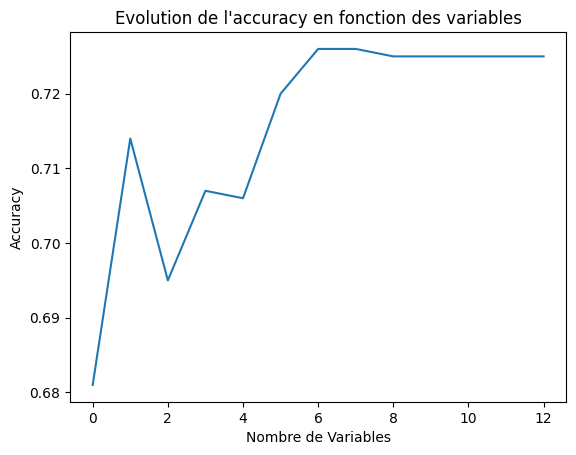

In [111]:
# Initialisation d'un classifieur KNN avec 5 voisins
KNN = KNeighborsClassifier(n_neighbors=5)

# Création d'un tableau pour stocker les scores d'accuracy
# scores aura une taille égale au nombre total de variables
scores = np.zeros(X_train.shape[1])  

# Boucle sur le nombre de variables à utiliser (de 1 à toutes les variables)
for f in np.arange(0, X_train.shape[1]):  
    # Sélection des f+1 variables les plus importantes selon l'analyse précédente
    # sorted_idx contient les indices des variables triées par importance décroissante
    X1_f = X_train[:, sorted_idx[:f+1]]  # Données d'entraînement avec f+1 meilleures variables
    X2_f = X_test[:, sorted_idx[:f+1]]   # Données de test avec les mêmes f+1 variables
    
    # Entraînement du modèle KNN sur le sous-ensemble de variables
    KNN.fit(X1_f, y_train) 
    
    # Prédiction sur les données de test
    YKNN = KNN.predict(X2_f) 
    
    # Calcul et stockage de l'accuracy (arrondie à 3 décimales)
    scores[f] = np.round(accuracy_score(y_test, YKNN), 3)  
    
# Visualisation de l'évolution de l'accuracy
plt.plot(scores) 
plt.xlabel("Nombre de Variables") 
plt.ylabel("Accuracy") 
plt.title("Evolution de l'accuracy en fonction des variables") 
plt.show()

# Cette analyse permet de :
# 1. Identifier le nombre optimal de variables à utiliser
# 2. Vérifier si toutes les variables sont nécessaires ou si un sous-ensemble suffit
# 3. Comprendre comment l'ajout de variables affecte la performance du modèle

### Troisième fonction – Explicabilité avec SHAP

In [112]:
def shap_explainability(model, X_train, X_test, feature_names):
    """
    Troisième fonction: Explicabilité avec SHAP
    
    Parameters:
    -----------
    model : modèle sklearn
        Modèle entraîné à expliquer
    X_train : array-like
        Données d'entraînement (pour l'initialisation de l'explainer)
    X_test : array-like
        Données de test (pour le calcul des valeurs SHAP)
    feature_names : list
        Noms des variables
        
    Returns:
    --------
    explainer : objet SHAP explainer
        Explainer SHAP initialisé
    shap_values : array
        Valeurs SHAP calculées
    """
    try:
        # Importation de la bibliothèque SHAP (doit être installée séparément)
        import shap
        print("=== TROISIÈME FONCTION: EXPLICABILITÉ SHAP ===")
        
        # Vérification que l'objet passé est bien un modèle sklearn
        if not hasattr(model, 'predict'):
            raise ValueError("L'objet passé n'est pas un modèle sklearn valide")
        
        # Création de l'explainer SHAP (KernelExplainer est générique pour tout modèle)
        # Utilisation d'un sous-échantillon de X_train (100 échantillons) pour accélérer le calcul
        explainer = shap.KernelExplainer(model.predict, X_train[:100])
        
        # Calcul des valeurs SHAP pour un sous-échantillon de X_test (30 échantillons)
        shap_values = explainer.shap_values(X_test[:30])
        
        # Graphique d'importance globale des variables
        plt.figure(figsize=(12, 8))
        shap.summary_plot(shap_values, X_test[:30], feature_names=feature_names, show=False)
        plt.title("Importance des variables (SHAP)")
        plt.tight_layout()
        plt.show()
        
        print(" Analyse SHAP réussie!")
        return explainer, shap_values
        
    except Exception as e:
        # Gestion des erreurs (si SHAP n'est pas installé ou échoue)
        print(f" Erreur SHAP: {e}")
        print("Utilisation d'une méthode alternative...")
        # Appel d'une méthode alternative d'explicabilité
        return alternative_explainability_simple(model, X_train, y_train, feature_names)

def alternative_explainability_simple(model, X_train, y_train, feature_names):
    """
    Alternative si SHAP échoue - Importance par permutation
    
    Parameters:
    -----------
    model : modèle sklearn
        Modèle entraîné
    X_train : array-like
        Données d'entraînement
    y_train : array-like
        Étiquettes d'entraînement
    feature_names : list
        Noms des variables
        
    Returns:
    --------
    result : objet permutation_importance
        Résultats de l'importance par permutation
    sorted_idx : array
        Indices des variables triées par importance
    """
    from sklearn.inspection import permutation_importance
    
    print("=== MÉTHODE ALTERNATIVE: IMPORTANCE PAR PERMUTATION ===")
    
    # Calcul de l'importance par permutation
    # Cette méthode perturbe aléatoirement chaque variable et mesure l'impact sur la performance
    result = permutation_importance(model, X_train, y_train, n_repeats=10, random_state=1)
    sorted_idx = result.importances_mean.argsort()[::-1]  # Tri décroissant
    
    # Graphique de l'importance des variables
    plt.figure(figsize=(12, 8))
    y_pos = np.arange(len(feature_names))
    plt.barh(y_pos, result.importances_mean[sorted_idx])
    plt.yticks(y_pos, np.array(feature_names)[sorted_idx])
    plt.xlabel("Importance par permutation")
    plt.title("Importance des variables (Alternative)")
    plt.gca().invert_yaxis()  # Inversion de l'axe Y pour avoir la plus importante en haut
    plt.tight_layout()
    plt.show()
    
    # Affichage détaillé du classement
    print("Classement des variables:")
    for i, idx in enumerate(sorted_idx):
        print(f"{i+1:2d}. {feature_names[idx]:15}: {result.importances_mean[idx]:.4f}")
    
    return result, sorted_idx

In [113]:
def shap_explainability_random_forest(X_train, X_test, y_train, feature_names):
    """
    Version avec Random Forest pour SHAP - CORRIGÉE
    
    Cette fonction utilise un Random Forest pour calculer les valeurs SHAP,
    ce qui est plus stable que KernelExplainer pour certains modèles.
    
    Parameters:
    -----------
    X_train : array-like
        Données d'entraînement
    X_test : array-like
        Données de test
    y_train : array-like
        Étiquettes d'entraînement
    feature_names : list
        Noms des variables
        
    Returns:
    --------
    explainer : objet SHAP TreeExplainer
        Explainer SHAP pour le Random Forest
    shap_values : array
        Valeurs SHAP calculées
    rf_model : modèle RandomForestClassifier
        Modèle Random Forest entraîné
    """
    try:
        # Importation de SHAP (doit être installé)
        import shap
        print("=== EXPLICABILITÉ SHAP AVEC RANDOM FOREST ===")
        
        # Importation de RandomForestClassifier
        from sklearn.ensemble import RandomForestClassifier
        
        # Création et entraînement d'un Random Forest
        rf_model = RandomForestClassifier(
            n_estimators=100,       # 100 arbres (équilibre performance/temps)
            max_depth=10,           # Profondeur maximale des arbres
            random_state=1          # Reproductibilité
        )
        rf_model.fit(X_train, y_train)
        
        # Création de l'explainer SHAP spécifique aux arbres
        # TreeExplainer est optimisé pour les modèles basés sur des arbres
        explainer = shap.TreeExplainer(rf_model)
        
        # Calcul des valeurs SHAP sur un échantillon des données de test
        X_test_sample = X_test[:100]  # Limité à 100 échantillons pour la performance
        shap_values = explainer.shap_values(X_test_sample)
        
        # Affichage des informations de débogage sur la structure des données
        print(f"Shape X_test_sample: {X_test_sample.shape}")
        print(f"Type de shap_values: {type(shap_values)}")
        if isinstance(shap_values, list):
            print(f"Longueur liste shap_values: {len(shap_values)}")
            for i, sv in enumerate(shap_values):
                print(f"  shap_values[{i}].shape: {sv.shape}")
        
        # Graphique principal - visualisation détaillée des valeurs SHAP
        plt.figure(figsize=(12, 8))
        
        # Gestion des différents formats de retour de SHAP
        if isinstance(shap_values, list) and len(shap_values) == 2:
            # Classification binaire : shap_values est une liste [classe_0, classe_1]
            # On utilise généralement shap_values[1] pour la classe positive
            print("Classification binaire détectée")
            shap.summary_plot(shap_values[1], X_test_sample, 
                            feature_names=feature_names, 
                            show=False)
        else:
            # Autres cas (classification multi-classes ou format différent)
            print("Format de shap_values différent")
            shap.summary_plot(shap_values, X_test_sample, 
                            feature_names=feature_names, 
                            show=False)
        
        plt.title("Importance SHAP des variables (Random Forest)")
        plt.tight_layout()
        plt.show()
        
        # Graphique d'importance moyenne (diagramme à barres)
        plt.figure(figsize=(10, 6))
        if isinstance(shap_values, list) and len(shap_values) == 2:
            # Utilisation de la classe positive pour le diagramme à barres
            shap.summary_plot(shap_values[1], X_test_sample, 
                            feature_names=feature_names, 
                            plot_type="bar", 
                            show=False)
        else:
            shap.summary_plot(shap_values, X_test_sample, 
                            feature_names=feature_names, 
                            plot_type="bar", 
                            show=False)
        plt.title("Importance moyenne SHAP")
        plt.tight_layout()
        plt.show()
        
        # Calcul de la performance du modèle Random Forest
        from sklearn.metrics import accuracy_score
        y_pred_rf = rf_model.predict(X_test)
        accuracy = accuracy_score(y_test, y_pred_rf)
        print(f"Accuracy Random Forest: {accuracy:.4f}")
        
        print("✅ Analyse SHAP avec Random Forest réussie!")
        return explainer, shap_values, rf_model
        
    except Exception as e:
        # Gestion des erreurs (SHAP non installé, problème d'import, etc.)
        print(f"❌ Erreur Random Forest: {e}")
        print("Utilisation de la méthode alternative...")
        # Appel de la méthode alternative basée sur l'importance par permutation
        return alternative_explainability_simple(X_train, y_train, feature_names)

In [114]:
def shap_explainability_xgboost(X_train, X_test, y_train, feature_names):
    """
    Version optimisée avec XGBoost pour SHAP
    """
    try:
        import shap
        import xgboost as xgb
        print("=== EXPLICABILITÉ SHAP AVEC XGBOOST ===")
        
        # Entraîner XGBoost (très compatible avec SHAP)
        xgb_model = xgb.XGBClassifier(
            n_estimators=100,
            max_depth=6,
            learning_rate=0.1,
            random_state=1
        )
        xgb_model.fit(X_train, y_train)
        
        # Explainer SHAP pour XGBoost
        explainer = shap.TreeExplainer(xgb_model)
        shap_values = explainer.shap_values(X_test[:100])
                
        # Graphique 1: Importance détaillée
        plt.figure(figsize=(12, 8))
        if isinstance(shap_values, list) and len(shap_values) == 2:
            shap.summary_plot(shap_values[1], X_test[:100], feature_names=feature_names, show=False)
        else:
            shap.summary_plot(shap_values, X_test[:100], feature_names=feature_names, show=False)
        plt.title("Importance SHAP des variables (XGBoost)")
        plt.tight_layout()
        plt.show()
        
        # Graphique 2: Importance moyenne
        plt.figure(figsize=(10, 6))
        if isinstance(shap_values, list) and len(shap_values) == 2:
            shap.summary_plot(shap_values[1], X_test[:100], feature_names=feature_names, 
                            plot_type="bar", show=False)
        else:
            shap.summary_plot(shap_values, X_test[:100], feature_names=feature_names, 
                            plot_type="bar", show=False)
        plt.title("Importance moyenne SHAP")
        plt.tight_layout()
        plt.show()
        
        # Performance du modèle XGBoost
        from sklearn.metrics import accuracy_score
        y_pred_xgb = xgb_model.predict(X_test)
        accuracy = accuracy_score(y_test, y_pred_xgb)
        print(f"Accuracy XGBoost: {accuracy:.4f}")
        
        print("✅ Analyse SHAP avec XGBoost réussie!")
        return explainer, shap_values, xgb_model
        
    except ImportError:
        print("XGBoost non installé. Installation: pip install xgboost")
        return shap_explainability_random_forest(X_train, X_test, y_train, feature_names)
    except Exception as e:
        print(f"Erreur XGBoost: {e}")
        return shap_explainability_random_forest(X_train, X_test, y_train, feature_names)



Début de l'analyse SHAP...
Features: ['Seniority', 'Home', 'Time', 'Age', 'Marital', 'Records', 'Job', 'Expenses', 'Income', 'Assets', 'Debt', 'Amount', 'Price']

--- OPTION 1: XGBoost ---
=== EXPLICABILITÉ SHAP AVEC XGBOOST ===


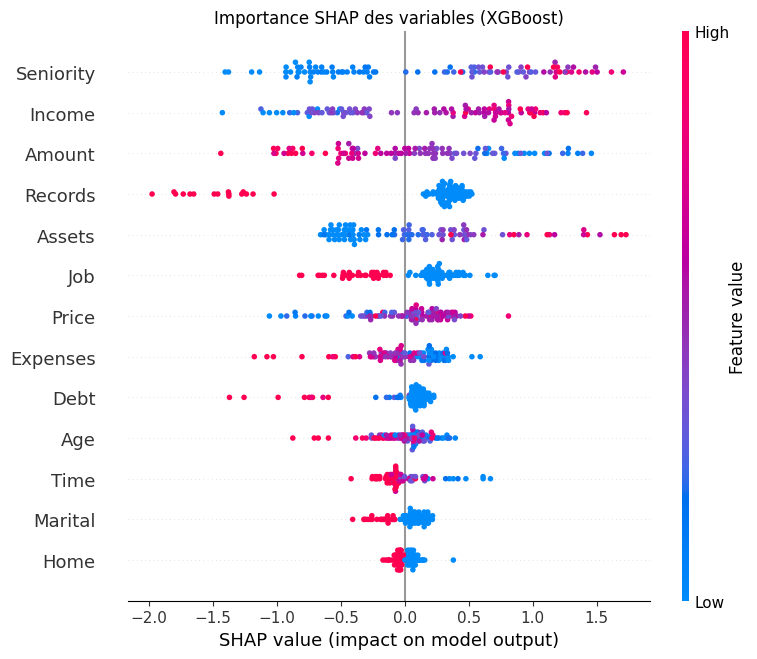

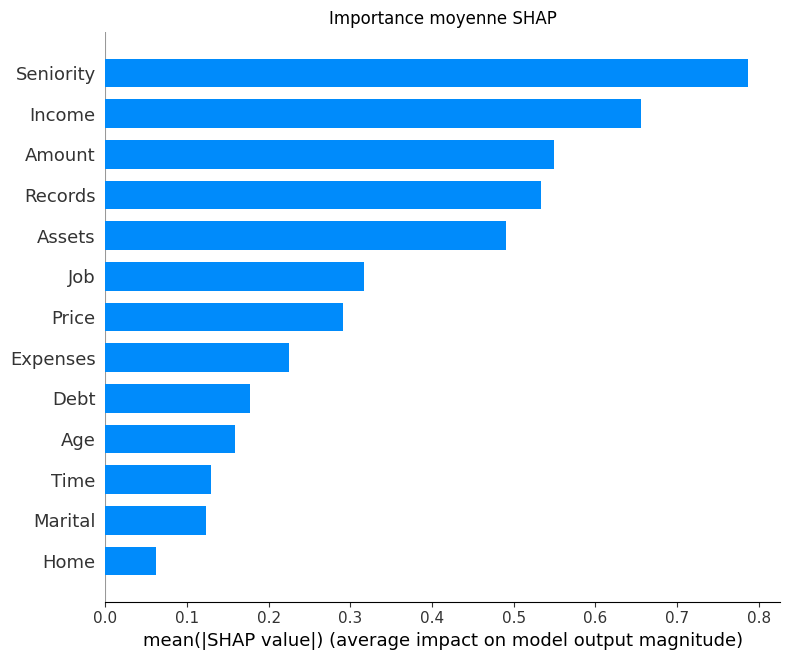

Accuracy XGBoost: 0.7879
✅ Analyse SHAP avec XGBoost réussie!


In [115]:
print("Début de l'analyse SHAP...")

# Préparation des noms de caractéristiques
# On prend toutes les colonnes sauf la dernière qui est la variable cible 'Status'
feature_names = df.columns.tolist()[:-1]  # Exclure 'Status' qui est la target
print(f"Features: {feature_names}")

print("\n--- OPTION 1: XGBoost ---")
# Appel de la fonction d'explicabilité avec XGBoost
explainer, shap_values, model = shap_explainability_xgboost(
    X_train, X_test, y_train, feature_names
)

# Note: Cette cellule suppose que la fonction shap_explainability_xgboost est définie
# Si elle n'existe pas, il faudra d'abord la définir ou utiliser une autre fonction


--- OPTION 2: Random Forest ---
=== EXPLICABILITÉ SHAP AVEC RANDOM FOREST ===
Shape X_test_sample: (100, 13)
Type de shap_values: <class 'numpy.ndarray'>
Format de shap_values différent


<Figure size 1200x800 with 0 Axes>

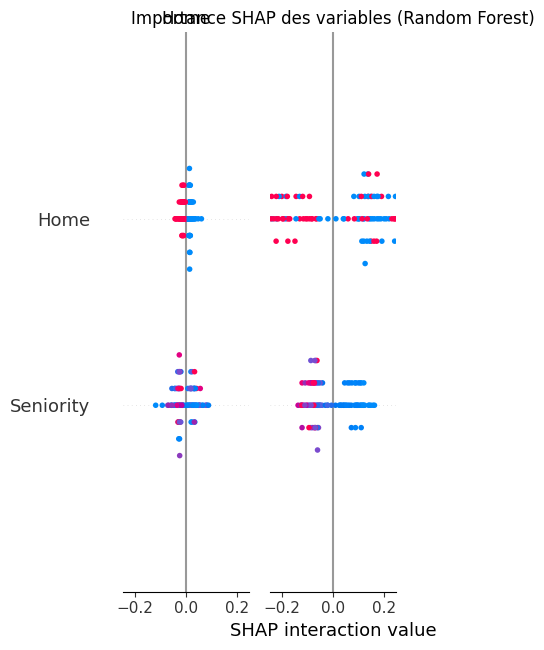

<Figure size 1000x600 with 0 Axes>

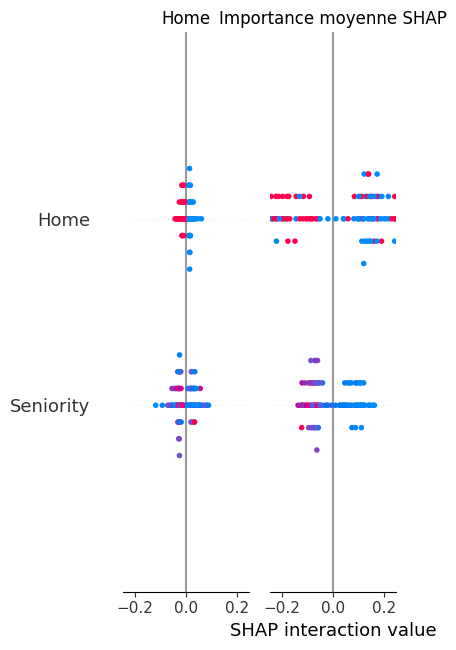

Accuracy Random Forest: 0.8007
✅ Analyse SHAP avec Random Forest réussie!


In [116]:
print("\n--- OPTION 2: Random Forest ---")
# Appel de la fonction d'explicabilité avec Random Forest
explainer, shap_values, model = shap_explainability_random_forest(
    X_train, X_test, y_train, feature_names
)

# La fonction shap_explainability_random_forest a été définie précédemment
# Elle retourne trois objets :
# 1. explainer : objet SHAP TreeExplainer pour interpréter les prédictions
# 2. shap_values : valeurs SHAP calculées montrant l'impact de chaque variable
# 3. model : modèle Random Forest entraîné pour référence ultérieure

In [117]:
# Vérification si l'analyse SHAP a réussi ou non
if explainer is None:
    # Si SHAP a échoué (explainer est None), utiliser la méthode alternative
    print("\n--- OPTION 3: Méthode alternative ---")
    from sklearn.ensemble import RandomForestClassifier
    
    # Création et entraînement d'un modèle Random Forest
    rf = RandomForestClassifier(n_estimators=100, random_state=1)
    rf.fit(X_train, y_train)
    
    # Appel de la méthode alternative d'explicabilité basée sur l'importance par permutation
    result, sorted_idx = alternative_explainability_simple(rf, X_train, y_train, feature_names)
else:
    # Si SHAP a réussi, afficher un message de confirmation
    print("\nAnalyse SHAP terminée avec succès.")

# Séparateur visuel pour clore la section d'analyse
print("=" * 60)


Analyse SHAP terminée avec succès.


## VI. Paramétrage des classifieurs

Dans cette dernière étape :
1.  Nous sélectionnons les meilleures variables identifiées précédemment.
2.  Nous optimisons les hyperparamètres du meilleur modèle (ex: KNN) via une **GridSearch**.

on import les bib necessaire

In [118]:
# Importation des modules nécessaires pour le réglage des hyperparamètres
from sklearn.model_selection import GridSearchCV  # Recherche exhaustive sur grille de paramètres
from sklearn.metrics import make_scorer, accuracy_score, precision_score  # Métriques d'évaluation
from sklearn.neighbors import KNeighborsClassifier  # Classifieur KNN pour optimisation
from sklearn.preprocessing import StandardScaler  # Normalisation des données

In [119]:
def custom_metric(y_true, y_pred):
    """
    Métrique personnalisée combinant accuracy et précision
    
    Parameters:
    -----------
    y_true : array-like
        Étiquettes réelles
    y_pred : array-like
        Étiquettes prédites
        
    Returns:
    --------
    float : Score combiné (moyenne entre accuracy et précision)
    """
    # Calcul de l'accuracy (proportion de prédictions correctes)
    acc = accuracy_score(y_true, y_pred)
    
    # Calcul de la précision (proportion de vrais positifs parmi les prédits positifs)
    # zero_division=0 : retourne 0 si division par zéro (aucun positif prédit)
    prec = precision_score(y_true, y_pred, zero_division=0)
    
    # Retourne la moyenne des deux métriques
    return (acc + prec) / 2

# Création d'un scorer compatible avec GridSearchCV à partir de la métrique personnalisée
custom_scorer = make_scorer(custom_metric)

In [120]:
# 2. Sélection des Variables Optimales
# KNN nécessite une normalisation pour bien fonctionner

# Définition des 8 variables les plus importantes identifiées précédemment
features_top8 = [
    "Income", "Seniority", "Price", "Amount", 
    "Age", "Assets", "Expenses", "Records"
]

# Nombre optimal de variables à utiliser (déterminé par analyse précédente)
n_optimal = 8
# indices_opt contient les indices des 8 variables les plus importantes
# sorted_idx provient de l'analyse d'importance des variables précédente
indices_opt = sorted_idx[:n_optimal] 

# Création des ensembles d'entraînement et de test avec seulement les variables optimales
X_train_opt = X_train[:, indices_opt]
X_test_opt = X_test[:, indices_opt]

# IMPORTANT POUR KNN : Normalisation des données réduites
# StandardScaler centre et réduit les données (moyenne=0, écart-type=1)
scaler_opt = StandardScaler()
X_train_opt_norm = scaler_opt.fit_transform(X_train_opt)  # Apprentissage et transformation sur train
X_test_opt_norm = scaler_opt.transform(X_test_opt)        # Transformation sur test (mêmes paramètres)

print(f"Optimisation du KNN sur les {n_optimal} variables les plus importantes (normalisées).")

# 3. Paramétrage avec GridSearchCV pour KNN
# On teste autour de k=5 puisque c'était votre meilleur résultat

# Grille de paramètres à tester pour KNN
param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 11, 13, 15, 20, 25, 30, 35],  # Différentes valeurs de k
    'weights': ['uniform', 'distance'],                         # Pondération uniforme ou par distance
    'metric': ['euclidean', 'manhattan', 'minkowski'],         # Mesures de distance
    'p': [1, 2] # 1=Manhattan, 2=Euclidean (pour minkowski)    # Paramètre p pour minkowski
}

# Initialisation du classifieur KNN
knn = KNeighborsClassifier()

print("\nRecherche des meilleurs paramètres pour KNN...")
# Configuration de la recherche sur grille
grid_search = GridSearchCV(
    estimator=knn,               # Modèle à optimiser
    param_grid=param_grid_knn,   # Grille de paramètres
    scoring=custom_scorer,       # Métrique d'évaluation personnalisée
    cv=5,                        # Validation croisée 5-fold
    n_jobs=-1,                   # Utilisation de tous les cœurs CPU
    verbose=1                    # Affichage des détails de la recherche
)

# Exécution de la recherche des meilleurs hyperparamètres
grid_search.fit(X_train_opt_norm, y_train)

# Affichage des résultats
print(f"\nMeilleurs paramètres : {grid_search.best_params_}")
print(f"Meilleur score ((Acc+Prec)/2) : {grid_search.best_score_:.4f}")

# Récupération du meilleur modèle entraîné
best_model_tuned = grid_search.best_estimator_

Optimisation du KNN sur les 8 variables les plus importantes (normalisées).

Recherche des meilleurs paramètres pour KNN...
Fitting 5 folds for each of 132 candidates, totalling 660 fits

Meilleurs paramètres : {'metric': 'manhattan', 'n_neighbors': 20, 'p': 1, 'weights': 'uniform'}
Meilleur score ((Acc+Prec)/2) : 0.7829


## VII Création de Pipeline et Sauvegarde du Modèle
1.  Nous construisons un **Pipeline** scikit-learn intégrant le pre-processing et le modèle, puis le sauvegardons (pickle) pour un usage futur.

In [121]:
import pickle  # Module pour la sérialisation/désérialisation d'objets Python
from sklearn.pipeline import Pipeline  # Pour créer des workflows de traitement
from sklearn.compose import ColumnTransformer  # Pour appliquer des transformations sur des colonnes spécifiques
from sklearn.preprocessing import StandardScaler  # Normalisation
from sklearn.neighbors import KNeighborsClassifier  # Classifieur KNN

In [122]:
def create_and_save_pipeline(X, y, indices_opt, best_params, filename="pipeline_credit_scoring.pkl"):
    """
    Crée un pipeline complet (Sélection -> Normalisation -> Modèle) et le sauvegarde.
    
    Parameters:
    -----------
    X : array-like
        Données d'entraînement complètes
    y : array-like
        Étiquettes d'entraînement
    indices_opt : list
        Indices des colonnes optimales à conserver
    best_params : dict
        Meilleurs paramètres trouvés pour le modèle KNN
    filename : str, optional
        Nom du fichier pour sauvegarder le pipeline
        
    Returns:
    --------
    pipeline : Pipeline sklearn
        Pipeline complet entraîné et prêt à l'emploi
    """
    print("=== CRÉATION DU PIPELINE ===")
    
    # 1. Définition de l'étape de sélection des colonnes
    # ColumnTransformer permet d'appliquer différentes transformations à différentes colonnes
    # Ici, nous gardons seulement les colonnes spécifiées par indices_opt
    feature_selector = ColumnTransformer(
        transformers=[
            ('selector', 'passthrough', indices_opt)  # Garde les colonnes sans transformation
        ],
        remainder='drop'  # Supprime toutes les autres colonnes non listées
    )
    
    # 2. Création du Pipeline séquentiel
    # Un pipeline enchaîne plusieurs étapes de traitement
    pipeline = Pipeline([
        ('feature_selection', feature_selector),  # Étape 1 : sélection des variables optimales
        ('scaler', StandardScaler()),             # Étape 2 : normalisation des variables sélectionnées
        ('classifier', KNeighborsClassifier(**best_params))  # Étape 3 : modèle KNN avec les meilleurs paramètres
    ])
    
    # 3. Entraînement du pipeline sur l'ensemble des données
    # Il est recommandé de réentraîner sur tout le dataset avant le déploiement en production
    print("Entraînement du pipeline sur l'ensemble des données...")
    pipeline.fit(X, y)  # L'entraînement se fait sur toutes les données disponibles
    
    # 4. Sauvegarde dans un fichier pickle
    # La sérialisation permet de sauvegarder le modèle pour une utilisation ultérieure
    print(f"Sauvegarde du modèle dans '{filename}'...")
    with open(filename, 'wb') as f:  # 'wb' = écriture en mode binaire
        pickle.dump(pipeline, f)     # Sérialisation de l'objet pipeline
        
    print("✅ Pipeline sauvegardé avec succès !")
    return pipeline

In [123]:
# ==============================================================================
# EXÉCUTION
# ==============================================================================

# Récupération des meilleurs paramètres trouvés à la Question 6
# Les paramètres optimaux identifiés par GridSearchCV
# Exemple : {'metric': 'manhattan', 'n_neighbors': 20, 'p': 1, 'weights': 'uniform'}
best_params_found = grid_search.best_params_

# Récupération des indices optimaux (Top 8) définis précédemment
# indices_opt = sorted_idx[:8]  
# Note: Assurez-vous que cette variable existe toujours (définie précédemment lors de la sélection des variables)

# Appel de la fonction pour créer et sauvegarder le pipeline
# On utilise X_train (original, non réduit) pour prouver que le pipeline gère la sélection
final_pipeline = create_and_save_pipeline(
    X_train,               # Données d'entraînement complètes (toutes les variables)
    y_train,               # Étiquettes d'entraînement
    indices_opt,           # Indices des 8 variables optimales à conserver
    best_params_found,     # Paramètres optimaux du modèle KNN
    filename="credit_scoring_model.pkl"  # Nom du fichier de sauvegarde
)

# Test rapide de chargement pour vérifier que la sauvegarde fonctionne
print("\nTest de chargement...")
# Ouverture du fichier en mode lecture binaire
with open("credit_scoring_model.pkl", 'rb') as f:  # 'rb' = lecture binaire
    loaded_pipeline = pickle.load(f)  # Désérialisation de l'objet pipeline
    
# Vérification sur un exemple (le premier individu du test)
pred = loaded_pipeline.predict(X_test[0:1])  # Prédiction sur le premier échantillon de test
print(f"Prédiction pour le premier individu du test : {pred[0]}")

=== CRÉATION DU PIPELINE ===
Entraînement du pipeline sur l'ensemble des données...
Sauvegarde du modèle dans 'credit_scoring_model.pkl'...
✅ Pipeline sauvegardé avec succès !

Test de chargement...
Prédiction pour le premier individu du test : 1.0
